### Cell 01 | 03 — Uniform elliptical strain-rate baseline

This notebook builds a fixed-geometry baseline using the updated local DDMpy solver and fits **observed four-hour strain-rate profiles only**. Strain is forward-predicted and reported as an independent diagnostic, not included in the objective.

F1 is the same tensile plane in both stages. F2 is a separate shear plane, inactive before T2. The nonparallel source setting is retained (strikes −0.8° and +0.6°, vertical dip, height 4000 ft, rectangular source lengths 3840 and 3800 ft). Ellipse lengths are adjusted to preserve the original along-strike edge-to-well gaps at the crossing elevation. Uniform-slip rectangular strips approximate the curved boundary; a 201/401/801-strip response check must pass before fitting.

Let x=clip((t−T1)/(T2−T1),0,1) and y=clip((t−T2)/(T3−T2),0,1). The baseline is

`opening(t) = A*x² + B*y`, `signed_shear(t) = −C*y²`, with A,B,C ≥ 0.

A is the opening at T2; B is the additional opening in stage 2; C is the final shear magnitude. All three amplitudes are fitted globally. The **time patterns are prescribed**, not independently inverted at each step. The old slip values (0.008 ft at T2, 0.024 ft opening and −0.03 ft shear at the old T3) are provenance/reference values, not hard constraints on the new ellipse fit.


For fixed geometry and linear DDM, strain is the unit-slip response times slip; strain rate is that same response times the analytic slip rate. Differentiate the prescribed laws exactly (do not difference noisy fitted strain). Fit the three amplitudes against native-sample four-hour mean rates, including the first window. The geometry, time laws and data are identical to notebook 01; only the fitted quantity changes.

### Revision record (append-only)

**2026-09-20 22:24:23 MDT** — reorganized every code section into a numbered title/introduction followed by numbered code; doubled plot typography; added recorded pressure-stage labels, stronger paired profile overlays and simulated-waterfall summaries.

**2026-09-20 22:28:05 MDT** — remove stage underline collisions; verify equal-height geometry rows; add same-observation rate comparison in notebook 06.

**2026-09-20 22:29:10 MDT** — retain physically equal aspect ratios in geometry views; audit common row edges with an explicit column-width exemption.

**2026-09-20 22:34:05 MDT** — user clarification: the Markdown title/introduction and following code cell share the same number; section numbers advance once per pair. Numerical code and executed results are unchanged.

### Cell 02 | Run instructions, environment and revision record

Revision: **2026-09-20 18:53:13 MDT**. Each title/introduction and its following code cell share one section number. Every code cell starts with its modification timestamp; retain older entries in this section for future changes.

Revision history: **2026-09-19 23:52 MDT** — initial two-step implementation, restored raw observations, mesh and derivative checks, sign-preserving sub-window reconstruction. **2026-09-20 17:19:01 MDT** — final figure review: move plane annotations and pressure legend out of the data, separate 3D labels, and retain the tested numerical model unchanged. **2026-09-20 18:53:13 MDT** — number all cells; share bottom-only date/time axes; update color limits; add pressure/slip figures and the separate strain-rate fitting pair.

1. Keep this project folder beside the existing `V1_DDM` folder in the local Fervo code tree.
2. Use the Python environment that runs the existing DDM notebooks. Restart the kernel and Run All in **01 → 02** for strain fitting, or **03 → 04** for four-hour strain-rate fitting, or **05 → 06** for two-hour strain-rate fitting. Each inversion notebook performs **zero DDM solves**. The rate pair can run without running the strain pair first.
3. Strain-fit results are written to `output/`; four-hour rate-fit results to `output/rate_fit/`; two-hour rate-fit results to `output/rate_fit_2h/`. Observations and fixed unit responses are shared. The private GitHub repository tracks only the six notebook sources via Git commit/push, with generated cell outputs cleared from publication copies. Raw DAS, microseismic, pressure data and generated results remain local.

Dependencies used on this machine: Python 3.14, NumPy 2.5.3, SciPy 1.18.1, pandas 3.0.5, Matplotlib 3.11.2, Plotly 7.0.0, nbformat 5.11.1, nbclient 0.11.0 and ipykernel 7.3.0; macOS 15.7.9 x86_64. Each run writes actual versions to its JSON report. Other systems are unverified.

Notebooks 01, 03 and 05 reuse the local `V1_DDM/ddm_backend.py` pinned DDMpy adapter and geometry diagnostics, plus their existing local dependencies (including JIN_pylib). This is a private, local-data research workflow, **not a standalone public distribution**. Original DDMpy provenance is retained in the generated report. No third-party code is relicensed or published here.

Selected documentation scope: source comments and environment/run notes. README/report metadata, a redistributable example, separate requirements file and licensing review are **out of scope**, per the notebook-source-only repository requirement; this is not a claim of full CWP compliance.

Time is fixed UTC−7, not daylight-saving-aware local time. All input events are in **2025**. T3 is **2025-03-06 00:00**; the 2026 date in the request is treated as a year typo. T1 is February 24 at 12:00 and T2 is February 28 at 00:00.

### Observation and plotting conventions

- Native DAS rate is in nanostrain/s, strain in millistrain, MD and DDM geometry in ft; slip exports are in mm. There are 57 four-hour windows, represented by their **center** times. Each profile is a sample mean, not an instantaneous profile.
- The verified early cache is retained. The late interval is rebuilt from actual March raw files with the established 3×7 median filter and common-mode subtraction, and must reproduce the overlapping cache. Raw file times are UTC; subtract seven hours exactly once.
- Integrate only valid adjacent samples, retaining the cumulative offset after gaps. Missing increments are not inferred; acquisition gaps remain masked. Subtract the first four-hour mean strain profile once. This deliberately replaces the older reset-to-zero-after-each-gap integration, which is incompatible with interpreting an independent fit as one continuous slip history.
- Waterfall backgrounds use **10-minute sample means** for display only. Inversion and four-hour overlays use all native samples. Small MD is at the top, large MD at the bottom. All rate panels share ±0.3 nanostrain/s and all strain panels share ±0.15 millistrain. Gray means missing, not zero. Black solid profiles are observations; green dashed profiles are models; both share one wiggle scale for each quantity. Linked time axes show ticks and labels only at the bottom: month/day/year on line 1, hour:minute on line 2. A separate two-panel pressure/slip figure uses the same convention.
- The upper curves are injection-well **pressure**, not volumetric injection rate. No flow-rate record is relabeled as pressure or vice versa.
- These are exploratory fit diagnostics. Improved training residuals do not establish fracture uniqueness, geomechanical causality or uncertainty bounds. Depth samples and integrated strain are correlated; unweighted least squares is not a statistical likelihood model.

### Current figure and fitting notes

The figures test how the inferred slip history reproduces measured depth profiles in the context of recorded injection pressure. Pressure is context, the rate waterfall shows rate agreement, and strain shows cumulative consistency; these fits do not establish causation. The quantitative grid uses Python/Matplotlib and exports editable PDF/SVG plus 300 dpi PNG. All observations are retained on their existing support.

The pressure band uses **STAGENUMBER from the input records**, split into contiguous runs (repeated numbers are not merged). The three gauge files must agree before a shared stage band is drawn. A band is metadata, not an inference of pumping-well identity. Black observed lines and thicker dashed green simulated lines use identical offsets and a thin white contrast outline. Each figure includes a profile legend.

**2026-09-20 22:24:23 MDT** — reorganized every code section into a numbered title/introduction followed by numbered code; doubled plot typography; added recorded pressure-stage labels, stronger paired profile overlays and simulated-waterfall summaries.

### Cell 03 | Imports, paths and plotting settings

Load dependencies, choose the fitting objective and window length, and set text sizes to at least twice the previous values.

In [1]:
# Cell 03 | Modified 2026-09-20 22:34:05 MDT — Imports, paths and plotting settings
# Purpose: Load dependencies, choose the fitting objective and window length, and set text sizes to at least twice the previous values.
from pathlib import Path
import hashlib
import json
import platform
import sys
import warnings
import os
# Modified 2026-09-19 23:34 MDT — keep the Matplotlib cache inside the local project.
_mpl_cache=Path.cwd()/'output/.matplotlib'
_mpl_cache.mkdir(parents=True,exist_ok=True)
os.environ.setdefault('MPLCONFIGDIR',str(_mpl_cache))
import numpy as np
import pandas as pd
import scipy
from scipy.optimize import nnls
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.lines import Line2D
import matplotlib.patheffects as patheffects

PROJECT = Path.cwd()
V1 = PROJECT.parent/'V1_DDM'
if PROJECT.name == 'two_step_staging':
    V1 = PROJECT.parent
# Modified 2026-09-20 — isolate strain/rate fits while sharing immutable observations.
FIT_TARGET = 'rate'  # The rate-fit notebooks set this to 'rate'.
TARGET_INDEX = {'rate':0,'strain':1}[FIT_TARGET]
DATA_OUT = PROJECT/'output'
WINDOW_HOURS = 4
OUT = DATA_OUT if FIT_TARGET=='strain' else DATA_OUT/('rate_fit' if WINDOW_HOURS==4 else 'rate_fit_2h')
OUT.mkdir(parents=True,exist_ok=True)
T1, T2, T3 = map(pd.Timestamp, ['2025-02-24 12:00','2025-02-28 00:00','2025-03-06 00:00'])
EDGES = pd.date_range(T1,T3,freq=f'{WINDOW_HOURS}h').as_unit('ns')
CENTERS = EDGES[:-1]+pd.Timedelta(hours=WINDOW_HOURS/2)
FT_TO_MM = 304.8
plt.rcParams.update({'font.family':'sans-serif','font.sans-serif':['DejaVu Sans'],'font.size':20,'axes.titlesize':24,'axes.labelsize':20,'xtick.labelsize':20,'ytick.labelsize':20,'legend.fontsize':20,'figure.titlesize':24,'pdf.fonttype':42,'svg.fonttype':'none'})

### Cell 04 | Observation support and mean profiles

Average every native sample within each fitting window. Integrate valid adjacent rates and preserve missing-data masks.

In [2]:
# Cell 04 | Modified 2026-09-20 22:34:05 MDT — Observation support and mean profiles
# Purpose: Average every native sample within each fitting window. Integrate valid adjacent rates and preserve missing-data masks.
def profiles(values, time, mask=None):
    """Return depth-by-window sample means on the supplied observation support."""
    values = np.asarray(values,float)
    if mask is not None:
        values = np.where(mask,values,np.nan)
    result=[]
    for lo,hi in zip(EDGES[:-1],EDGES[1:]):
        chunk=values[..., (time>=lo)&(time<hi)]
        count=np.isfinite(chunk).sum(axis=-1)
        result.append(np.divide(np.nansum(chunk,axis=-1),count,out=np.full(count.shape,np.nan),where=count>0))
    return np.stack(result,axis=-1)


def integrate_observed(rate,time):
    """Integrate valid adjacent rates to millistrain; hold offset, do not bridge gaps."""
    dt=np.diff(time.asi8)/1e9
    valid=np.isfinite(rate)
    increments=(rate[:,:-1]+rate[:,1:])*.5*dt/1e6
    increments=np.where(valid[:,:-1]&valid[:,1:]&(dt[None,:]<=20),increments,0.)
    strain=np.column_stack([np.zeros(len(rate)),np.cumsum(increments,axis=1)])
    strain[~valid]=np.nan
    strain-=profiles(strain,time)[:,[0]]
    return strain


def load_observations():
    """Return saved rate, cumulative strain, depths, time, support and 4-hour profiles."""
    with np.load(DATA_OUT/'observations_through_20250306.npz') as z:
        rate,depth,time=z['rate'],z['depth'],pd.DatetimeIndex(z['time_ns'])
    strain=integrate_observed(rate,time)
    support=np.isfinite(rate)
    assert np.all(support==support[[0]]), 'Partial-depth gaps require depth-specific slip averaging.'
    assert time.is_monotonic_increasing and not time.has_duplicates
    return dict(rate=rate,strain=strain,depth=depth,time=time,support=support,
                profiles=np.stack([profiles(rate,time),profiles(strain,time)]))

### Cell 05 | Forward model and residual metrics

Define the prescribed time laws, convert component slip to strain/rate, and score the predicted profiles.

In [3]:
# Cell 05 | Modified 2026-09-20 22:34:05 MDT — Forward model and residual metrics
# Purpose: Define the prescribed time laws, convert component slip to strain/rate, and score the predicted profiles.
def time_laws(time):
    """Return three unit-amplitude time laws and analytic derivatives per second."""
    t=pd.DatetimeIndex(time)
    d1,d2=(T2-T1).total_seconds(),(T3-T2).total_seconds()
    x=np.clip((t-T1).total_seconds().to_numpy()/d1,0,1)
    y=np.clip((t-T2).total_seconds().to_numpy()/d2,0,1)
    laws=np.array([x*x,y,y*y])
    speeds=np.array([np.where((t>=T1)&(t<T2),2*x/d1,0),
                     np.where((t>=T2)&(t<=T3),1/d2,0),
                     np.where((t>=T2)&(t<=T3),2*y/d2,0)])
    return laws,speeds


def forward_components(unit,amounts,speeds,obs,reference=None):
    """Map signed slips/speeds in mm to component strain and rate, with one reference."""
    strain=unit[:,:,None]*amounts[:,None,:]/FT_TO_MM*1e3
    rate=unit[:,:,None]*speeds[:,None,:]/FT_TO_MM*1e9
    if reference is None:
        reference=profiles(amounts,obs['time'],obs['support'][[0]])[:,0]
    strain-=unit[:,:,None]*reference[:,None,None]/FT_TO_MM*1e3
    pp=np.stack([profiles(rate,obs['time'],obs['support']),profiles(strain,obs['time'],obs['support'])],axis=1)
    return dict(amounts=amounts,speeds=speeds,rate=rate,strain=strain,profiles=pp,reference=reference)


def fit_metrics(obs,model):
    """Return unweighted profile RMSE and target-RMS-normalized RMSE for both quantities."""
    rows=[]
    for q,(name,units) in enumerate([('rate','nanostrain/s'),('strain','millistrain')]):
        y=obs['profiles'][q]; pred=model['profiles'][:,q].sum(axis=0)
        mask=np.isfinite(y)&np.isfinite(pred)
        if q==1: mask[:,0]=False
        rmse=np.sqrt(np.mean((pred[mask]-y[mask])**2))
        rows.append(dict(quantity=name,units=units,rmse=float(rmse),relative_rmse=float(rmse/np.sqrt(np.mean(y[mask]**2))),samples=int(mask.sum()),fitted=q==TARGET_INDEX))
    return pd.DataFrame(rows)

### Cell 06 | Injection pressure and figure exports

Load recorded hydraulic-stage numbers and save local figures with shared-axis alignment checks.

In [4]:
# Cell 06 | Modified 2026-09-20 22:34:05 MDT — Injection pressure and figure exports
# Modified 2026-09-20 22:29:10 MDT — document physical-aspect geometry column exemption.
# Modified 2026-09-20 22:28:05 MDT — refine rendered label clearance and verification.
# Purpose: Load recorded hydraulic-stage numbers and save local figures with shared-axis alignment checks.
def pressure_data():
    """Read three local injection-well pressure records; return an unshifted MST table."""
    root=V1.parents[2]/'Aleksei/Data/Bearskin Stimulation Data'
    frames=[]
    for well,color in [('1-IA','#E69F00'),('3-PA','#7B3294'),('4-PB','#D55E00')]:
        frame=pd.read_csv(root/f'Bearskin {well} Pressure.csv')
        frame['time']=pd.to_datetime(frame.MSTTIMESTAMP)
        frame['stage_number']=pd.to_numeric(frame.STAGENUMBER,errors='coerce')
        frame['pressure_psi']=pd.to_numeric(frame.PRESSURE_PSI,errors='coerce')
        frame=frame.loc[frame.time.between(T1,T3)].copy()
        frame['well']='Bearskin '+well; frame['color']=color
        frames.append(frame[['time','pressure_psi','well','color','stage_number']])
    return pd.concat(frames,ignore_index=True)


def save_figure(fig,name,axes=None):
    """Save PNG/PDF plus measured axes rectangles; reject inconsistent shared x extents."""
    fig.canvas.draw()
    boxes=[]
    for ax in (axes or []):
        box=ax.get_position()
        boxes.append(dict(left_pt=box.x0*fig.get_figwidth()*72,right_pt=box.x1*fig.get_figwidth()*72,bottom_pt=box.y0*fig.get_figheight()*72,top_pt=box.y1*fig.get_figheight()*72))
    if len(boxes)>1:
        assert np.ptp([b['left_pt'] for b in boxes])<1.5
        assert np.ptp([b['right_pt'] for b in boxes])<1.5
        # Optional local figure QA; not a dependency for normal notebook execution.
        qa_scripts=os.environ.get('FERVO_FIGURE_QA_SCRIPTS')
        if qa_scripts:
            if qa_scripts not in sys.path: sys.path.insert(0,qa_scripts)
            from audit_panel_alignment import require_matplotlib_panel_alignment
            require_matplotlib_panel_alignment(fig,axes=axes,json_out=OUT/f'{name}_alignment.json',strict=True)
    if axes is None and len(fig.axes)>=4 and os.environ.get('FERVO_FIGURE_QA_SCRIPTS'):
        qa_scripts=os.environ['FERVO_FIGURE_QA_SCRIPTS']
        if qa_scripts not in sys.path: sys.path.insert(0,qa_scripts)
        from audit_panel_alignment import require_matplotlib_panel_alignment
        # Equal-aspect physical projections intentionally differ in width; compare row edges.
        require_matplotlib_panel_alignment(fig,axes=fig.axes[:4],panel_ids=['a','b','c','d'],
            row_groups=[['a','b'],['c','d']],column_groups=[],
            exemptions=[{'panels':['a','b','c','d'],'checks':['column'],
                         'reason':'Equal physical aspect ratios in XY/XZ/YZ and a 3D view require different widths; row heights and edges remain comparable.'}],
            json_out=OUT/f'{name}_alignment.json',strict=True)
    (OUT/f'{name}_layout.json').write_text(json.dumps(boxes,indent=2))
    fig.savefig(OUT/f'{name}.png',dpi=300)
    fig.savefig(OUT/f'{name}.pdf',dpi=300)
    fig.savefig(OUT/f'{name}.svg',dpi=300)
    display(fig)
    plt.close(fig)

### Cell 07 | Visible waterfall profiles

Overlay all observed profiles in black and simulated profiles in thicker dashed green, with a common amplitude scale and legend.

In [5]:
# Cell 07 | Modified 2026-09-20 22:34:05 MDT — Visible waterfall profiles
# Purpose: Overlay all observed profiles in black and simulated profiles in thicker dashed green, with a common amplitude scale and legend.
def profile_legend(fig, y=.985):
    """Use one figure-level key for the paired profile curves."""
    handles=[Line2D([],[],color='black',lw=1.6,label='Observed profile'),
             Line2D([],[],color='#00852B',lw=2.4,ls='--',label='Simulated profile')]
    fig.legend(handles=handles,loc='upper center',bbox_to_anchor=(.5,y),ncol=2,frameon=False)


def waterfall(ax,obs,model,quantity,background='observed',scale=None):
    """Draw a waterfall and every fitted window profile at its center time."""
    key=('rate','strain')[quantity]
    values=obs[key] if background=='observed' else model[key].sum(axis=0)
    values=np.where(obs['support'],values,np.nan)
    # Display-only 10-minute means; profile fitting retains all native samples.
    frame=pd.DataFrame(values.T,index=obs['time']).resample('10min').mean()
    cmap=plt.get_cmap('seismic').copy(); cmap.set_bad('#bbbbbb')
    lim=(.3,.15)[quantity]
    image=ax.pcolormesh(frame.index,obs['depth'],frame.to_numpy().T,cmap=cmap,vmin=-lim,vmax=lim,shading='auto',rasterized=True)
    observed=obs['profiles'][quantity]; simulated=model['profiles'][:,quantity].sum(axis=0)
    if scale is None:
        scale=max(np.nanpercentile(np.abs(np.r_[observed.ravel(),simulated.ravel()]),98),1e-12)
    # A common amplitude-to-time mapping for observed/simulated; halve spacing at 2 h.
    width_days=.055*(WINDOW_HOURS/4)/scale
    x=mdates.date2num(CENTERS)
    for j,anchor in enumerate(x):
        ax.plot(anchor+observed[:,j]*width_days,obs['depth'],color='black',lw=1.6,zorder=5,
                path_effects=[patheffects.Stroke(linewidth=2.8,foreground='white'),patheffects.Normal()])
        ax.plot(anchor+simulated[:,j]*width_days,obs['depth'],color='#00852B',ls='--',lw=2.4,zorder=6,
                path_effects=[patheffects.Stroke(linewidth=3.5,foreground='white'),patheffects.Normal()])
    ax.set(ylim=(10500,10200),xlim=(T1,T3),ylabel='Measured depth (ft)')
    ax.set_title(f'{background.capitalize()} {key} waterfall | {WINDOW_HOURS}-hour mean profiles',pad=48)
    for t,label in [(T1,'T1'),(T2,'T2'),(T3,'T3')]:
        ax.axvline(t,color='#B36B00',ls='--',lw=1.2)
        ax.text(t,1.012,label,transform=ax.get_xaxis_transform(),color='#996000',fontsize=16,ha='center',va='bottom')
    geometry_file=OUT/'fixed_plane_geometry.csv'
    if geometry_file.exists():
        for k,row in pd.read_csv(geometry_file).iterrows():
            color=['#B36B00','teal'][k]
            ax.axhline(row.plane_crossing_md_ft,color=color,ls='--',lw=1.2)
            ax.annotate(f'F{k+1} plane extension: {row.plane_crossing_md_ft:.1f} ft',xy=(.13+.43*k,1),xycoords='axes fraction',xytext=(0,10),textcoords='offset points',ha='left',va='bottom',fontsize=16,color=color)
    return image

### Cell 08 | Pressure, slip and shared time axes

Label contiguous recorded stage intervals above the pressure curves and align pressure and continuous slip histories.

In [6]:
# Cell 08 | Modified 2026-09-20 22:34:05 MDT — Pressure, slip and shared time axes
# Modified 2026-09-20 22:28:05 MDT — refine rendered label clearance and verification.
# Purpose: Label contiguous recorded stage intervals above the pressure curves and align pressure and continuous slip histories.
def pressure_slip_panels(axes,obs,model,injection,title):
    """Plot recorded pressure/stage metadata and continuous tensile/shear slip."""
    for well,frame in injection.groupby('well',sort=False):
        axes[0].plot(frame.time,frame.pressure_psi,lw=1.5,color=frame.color.iloc[0],label=well)
    # The supplied files repeat the same stage timeline across all three gauges.
    # Check that agreement before drawing a shared band; never infer stages from peaks.
    stage_table=injection.pivot(index='time',columns='well',values='stage_number').sort_index()
    assert stage_table.nunique(axis=1,dropna=False).max()==1, 'Gauge stage records disagree.'
    stage=stage_table.iloc[:,0]
    changes=stage.ne(stage.shift()) & ~(stage.isna() & stage.shift().isna())
    runs=[]
    for _,part in stage.groupby(changes.cumsum()):
        if part.notna().any():
            runs.append((part.index[0],part.index[-1],int(part.iloc[0])))
    max_pressure=float(injection.pressure_psi.max())
    axes[0].set_ylim(0,max_pressure*1.50)
    for i,(lo,hi,number) in enumerate(runs):
        center=lo+(hi-lo)/2
        # Two alternating lanes avoid collisions between adjacent short stages.
        level=max_pressure*(1.19+.18*(i%2))
        axes[0].text(center,level,str(number),ha='center',va='center',fontsize=18)
    axes[0].set(ylabel='Injection pressure (psi)')
    axes[0].set_title('Injection pressure | recorded stage numbers above curves',pad=60)
    axes[0].legend(ncol=3,fontsize=20,loc='lower left',bbox_to_anchor=(0,1.015),borderaxespad=0,frameon=False)
    twin=axes[1].twinx()
    axes[1].plot(obs['time'],model['amounts'][0],color='royalblue',lw=2,label='Tensile opening')
    twin.plot(obs['time'],np.abs(model['amounts'][1]),color='firebrick',lw=2,label='Shear magnitude')
    axes[1].set(ylabel='Tensile slip (mm)')
    axes[1].set_title(title,pad=58)
    twin.set_ylabel('|Shear slip| (mm)',color='firebrick')
    axes[1].yaxis.label.set_color('royalblue')
    axes[1].legend(handles=[Line2D([],[],color='royalblue',label='Tensile'),Line2D([],[],color='firebrick',label='|Shear|')],loc='lower left',bbox_to_anchor=(0,1.01),ncol=2,frameon=False)
    for ax in axes[:2]: ax.axvline(T2,color='#B36B00',ls='--',lw=1.2)
    return twin


def shared_time_axis(axes):
    """Show date/time ticks only on the bottom shared axis, in fixed UTC−7."""
    for ax in axes: ax.set_xlim(T1,T3)
    axes[-1].xaxis.set_major_locator(mdates.DayLocator())
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%m/%d/%y\n%H:%M'))
    for ax in axes[:-1]:
        assert ax.get_shared_x_axes().joined(ax,axes[-1])
        ax.tick_params(axis='x',which='both',bottom=False,top=False,labelbottom=False,labeltop=False)
        ax.set_xlabel('')
    axes[-1].tick_params(axis='x',which='both',bottom=True,labelbottom=True,top=False,labeltop=False)
    axes[-1].set_xlabel('Time (fixed UTC−7)')

### Cell 09 | Diagnostic figure layouts

Create pressure/slip figures and combined observed or simulated waterfall figures with enlarged labels.

In [7]:
# Cell 09 | Modified 2026-09-20 22:34:05 MDT — Diagnostic figure layouts
# Purpose: Create pressure/slip figures and combined observed or simulated waterfall figures with enlarged labels.
def plot_pressure_slip(obs,model,injection,name):
    """Save pressure with recorded stages and slip, sharing one time axis."""
    fig,axes=plt.subplots(2,1,figsize=(30,11),sharex=True)
    fig.subplots_adjust(left=.075,right=.90,bottom=.13,top=.84,hspace=.65)
    pressure_slip_panels(axes,obs,model,injection,'Tensile and shear slip history')
    shared_time_axis(axes)
    save_figure(fig,f'{name}_pressure_slip',list(axes))
    return fig


def plot_summary(obs,model,injection,name,background='observed'):
    """Align pressure, slip, and two diagnostic waterfalls on one timeline."""
    fig=plt.figure(figsize=(30,22))
    gs=fig.add_gridspec(4,2,height_ratios=[1.25,1,2.3,2.3],width_ratios=[1,.016],left=.075,right=.91,bottom=.065,top=.87,hspace=.62,wspace=.06)
    axes=[fig.add_subplot(gs[0,0])]
    axes.extend(fig.add_subplot(gs[i,0],sharex=axes[0]) for i in range(1,4))
    pressure_slip_panels(axes,obs,model,injection,'Tensile and shear slip history')
    for q,ax in enumerate(axes[2:]):
        im=waterfall(ax,obs,model,q,background=background)
        fig.colorbar(im,cax=fig.add_subplot(gs[q+2,1]),label=('Rate (nanostrain/s)','Strain (millistrain)')[q])
    profile_legend(fig,y=.98)
    shared_time_axis(axes)
    suffix='' if background=='observed' else '_simulated_summary'
    save_figure(fig,name+suffix,axes)
    return fig


def plot_comparison(obs,model,name):
    """Compare observed/simulated waterfalls with the same color and wiggle scales."""
    for background in ['observed','simulated']:
        fig=plt.figure(figsize=(30,15))
        gs=fig.add_gridspec(2,2,width_ratios=[1,.016],left=.075,right=.91,bottom=.105,top=.85,hspace=.40,wspace=.06)
        axes=[]
        for q in range(2):
            ax=fig.add_subplot(gs[q,0],sharex=axes[0] if axes else None); axes.append(ax)
            im=waterfall(ax,obs,model,q,background)
            fig.colorbar(im,cax=fig.add_subplot(gs[q,1]),label=('Rate (nanostrain/s)','Strain (millistrain)')[q])
        profile_legend(fig,y=.98)
        shared_time_axis(axes)
        save_figure(fig,f'{name}_{background}',axes)

### Cell 10 | Component tables and runtime provenance

Export per-window component slips, strain and rate profiles, residual metrics, and actual dependency versions.

In [8]:
# Cell 10 | Modified 2026-09-20 22:34:05 MDT — Component tables and runtime provenance
# Purpose: Export per-window component slips, strain and rate profiles, residual metrics, and actual dependency versions.
def export_components(obs,model,prefix,coefficients=None):
    """Write per-component, per-4h slip, strain and strain-rate CSVs and a compact NPZ."""
    mean_amount=profiles(model['amounts'],obs['time'],obs['support'][[0]])
    mean_speed=profiles(model['speeds'],obs['time'],obs['support'][[0]])
    for k,component in enumerate(['tensile','shear']):
        slips=pd.DataFrame({'window_start':EDGES[:-1],'window_end':EDGES[1:],'center_time':CENTERS,'mean_signed_slip_mm':mean_amount[k],'mean_absolute_slip_mm':np.abs(mean_amount[k]),'mean_signed_slip_rate_mm_s':mean_speed[k]})
        if coefficients is not None: slips[f'{FIT_TARGET}_baseline_scale']=coefficients[k]
        slips.to_csv(OUT/f'{prefix}_{component}_slip_4h.csv',index=False)
        frame=pd.DataFrame({'center_time':np.repeat(CENTERS,len(obs['depth'])),'md_ft':np.tile(obs['depth'],len(CENTERS)),
            'strain_millistrain':model['profiles'][k,1].T.ravel(),'strain_rate_nanostrain_s':model['profiles'][k,0].T.ravel()})
        frame.to_csv(OUT/f'{prefix}_{component}_profiles_4h.csv',index=False)
    np.savez_compressed(OUT/f'{prefix}_profiles_4h.npz',depth_ft=obs['depth'],centers_ns=CENTERS.asi8,
                        component_profiles=model['profiles'],mean_slip_mm=mean_amount,mean_slip_rate_mm_s=mean_speed,observed_profiles=obs['profiles'])
    fit_metrics(obs,model).to_csv(OUT/f'{prefix}_metrics.csv',index=False)


def environment_report():
    """Return actual runtime and dependency versions; no claims about untested platforms."""
    return dict(system=platform.platform(),python=sys.version.split()[0],numpy=np.__version__,scipy=scipy.__version__,pandas=pd.__version__,matplotlib=matplotlib.__version__)

### Cell 11 | Restore and validate late observations

Load or restore the verified observations through T3; preserve acquisition gaps and check overlap with the earlier cache.

In [9]:
# Cell 11 | Modified 2026-09-20 22:34:05 MDT — Restore and validate late observations
# Purpose: Load or restore the verified observations through T3; preserve acquisition gaps and check overlap with the earlier cache.
# Modified 2026-09-19 America/Denver — restore actual March 4–6 raw LF-DAS data.
"""Build the extended, time-ordered observation cache; never pad missing days."""
from pathlib import Path
from io import BytesIO
from concurrent.futures import ThreadPoolExecutor, as_completed
import numpy as np
import pandas as pd
from scipy.signal import medfilt


def restore_observations(v1_dir, destination):
    """Read verified cache plus raw tail; save rate/depth/time and daily coverage."""
    v1_dir, destination = Path(v1_dir), Path(destination)
    destination.mkdir(parents=True, exist_ok=True)
    cache = destination / 'observations_through_20250306.npz'
    if cache.exists():
        with np.load(cache) as z:
            return z['rate'], z['depth'], pd.DatetimeIndex(z['time_ns'])
    with np.load(v1_dir/'output/shear_only/corrected_observations.npz') as z:
        old_rate, depth, old_time = z['rate'], z['depth'], pd.DatetimeIndex(z['time_ns'])
    raw = v1_dir.parents[2]/'Aleksei/Data/Gold 4-PB/DAS/LF-DAS NPY/NPY_G4-PB_MM_UTC_202503'
    cutoff = pd.Timestamp('2025-03-03 22:00')
    end = pd.Timestamp('2025-03-06 00:00')
    lo_stamp = (cutoff+pd.Timedelta('7h')-pd.Timedelta('5min')).strftime('%Y%m%d_%H%M%S')
    hi_stamp = (end+pd.Timedelta('7h')+pd.Timedelta('5min')).strftime('%Y%m%d_%H%M%S')
    files = sorted(p for p in raw.glob('*.npy') if lo_stamp <= p.stem.split('UTC_')[-1] <= hi_stamp)
    if not files:
        raise FileNotFoundError(f'No raw tail files: {raw}')
    starts = pd.to_datetime([p.stem.split('UTC_')[-1] for p in files], format='%Y%m%d_%H%M%S')
    # Modified 2026-09-19 23:42 MDT — pandas 3 may default to microseconds; storage is ns.
    raw_time = (pd.DatetimeIndex((starts.to_numpy()[:,None] + np.arange(5,60,10)[None,:]*np.timedelta64(1,'s')).ravel())-pd.Timedelta('7h')).as_unit('ns')
    # Sort individual samples before filtering; file timestamps can overlap.
    order = np.argsort(raw_time.asi8, kind='stable')
    sorted_time = raw_time[order]
    if sorted_time.has_duplicates:
        raise ValueError('Duplicate raw timestamps require an explicit aggregation policy.')
    inserts = np.r_[0, np.maximum(0, np.rint(np.diff(sorted_time.asi8)/1e10).astype(int)-1)]
    positions = np.arange(len(sorted_time))+np.cumsum(inserts)
    full_ns = np.empty(positions[-1]+1, np.int64)
    full_ns[positions] = sorted_time.asi8
    for k in np.flatnonzero(inserts):
        full_ns[positions[k-1]+1:positions[k]] = sorted_time.asi8[k-1]+np.arange(1,inserts[k]+1)*10_000_000_000
    time = pd.DatetimeIndex(full_ns)
    a = (14807-15)/(2255-52)
    lead = -a*(52-15/a)
    all_depth = np.linspace(lead,2304*a+lead,2304)
    reference = np.arange(int((1800-lead)/a),int((5000-lead)/a))
    target = np.flatnonzero((all_depth>=10200)&(all_depth<=10500))
    needed = np.unique(np.r_[reference-1,reference,reference+1,target-1,target,target+1])
    np.testing.assert_allclose(depth,all_depth[target])
    # Read in modest batches, reporting progress; no silent timeout-to-NaN fallback.
    raw_values = np.empty((len(raw_time),len(needed)))
    def read_file(index):
        """Read one NPY via a buffer; return its index and required depth samples."""
        return index,np.load(BytesIO(files[index].read_bytes()),allow_pickle=False)[:,needed]
    # Concurrent reads allow OneDrive-backed files to become available independently.
    with ThreadPoolExecutor(max_workers=16) as pool:
        futures=[pool.submit(read_file,i) for i in range(len(files))]
        for done,future in enumerate(as_completed(futures),1):
            index,values=future.result()
            raw_values[index*6:(index+1)*6]=values
            if done%120==0 or done==len(files):
                print(f'Raw tail: {done}/{len(files)} files',flush=True)
    block = np.full((len(needed),len(time)),np.nan)
    block[:,positions] = raw_values[order].T*(116*1000/10/8192)
    filtered = medfilt(block,kernel_size=(3,7))
    common = np.nanmedian(filtered[np.searchsorted(needed,reference)],axis=0)
    rate = filtered[np.searchsorted(needed,target)]-common
    gap = np.ones(len(time),bool)
    gap[positions] = False
    rate[:,gap] = np.nan
    for row in rate:
        missing = ~np.isfinite(row)&~gap
        valid = np.isfinite(row)&~gap
        row[missing] = np.interp(np.flatnonzero(missing),np.flatnonzero(valid),row[valid])
    overlap = (time>=cutoff)&(time<old_time.max()-pd.Timedelta('2min'))
    indices = old_time.get_indexer(time[overlap])
    valid = indices>=0
    delta = rate[:,overlap][:,valid]-old_rate[:,indices[valid]]
    print('Raw/cache overlap max absolute difference:',np.nanmax(np.abs(delta)),flush=True)
    np.testing.assert_allclose(delta,0,atol=1e-10,equal_nan=False)
    keep_old = old_time<cutoff
    keep_new = (time>=cutoff)&(time<end)
    rate = np.concatenate([old_rate[:,keep_old],rate[:,keep_new]],axis=1)
    time = old_time[keep_old].append(time[keep_new])
    assert time.is_monotonic_increasing and not time.has_duplicates
    assert time.max()>end-pd.Timedelta('1min'), 'Raw observations do not reach requested T3.'
    np.savez_compressed(cache,rate=rate,depth=depth,time_ns=time.asi8)
    coverage = pd.DataFrame({'time':time,'finite':np.isfinite(rate).all(axis=0)}).groupby(pd.Grouper(key='time',freq='D')).agg(samples=('finite','size'),finite_samples=('finite','sum'))
    coverage.to_csv(destination/'observation_daily_coverage.csv')
    print(coverage)
    return rate,depth,time



restore_observations(V1,DATA_OUT)

(array([[ 0.03511719,  0.02987793,  0.0359668 , ..., -0.00099121,
         -0.00113281, -0.01345215],
        [ 0.00722168,  0.01062012,  0.01670898, ..., -0.00099121,
         -0.00141602, -0.0271875 ],
        [ 0.00594727,  0.00821289,  0.01430176, ..., -0.0177002 ,
         -0.02987793, -0.03129395],
        ...,
        [-0.02959473, -0.02619629, -0.01656738, ...,  0.00410645,
          0.01033691,  0.00453125],
        [-0.02393066, -0.02053223, -0.01316895, ...,  0.00679688,
          0.01203613,  0.0090625 ],
        [-0.0092041 , -0.00764648, -0.00736328, ...,  0.00538086,
          0.01033691, -0.0087793 ]], shape=(44, 82086)),
 array([10205.44102218, 10212.15841797, 10218.87581376, 10225.59320955,
        10232.31060534, 10239.02800113, 10245.74539692, 10252.46279271,
        10259.1801885 , 10265.8975843 , 10272.61498009, 10279.33237588,
        10286.04977167, 10292.76716746, 10299.48456325, 10306.20195904,
        10312.91935483, 10319.63675062, 10326.35414641, 10333.0715

### Cell 12 | Fixed planes and uniform-slip DDM responses

Build the fixed tensile and shear planes and load or calculate mesh-converged unit DDM responses.

In [10]:
# Cell 12 | Modified 2026-09-20 22:34:05 MDT — Fixed planes and uniform-slip DDM responses
# Purpose: Build the fixed tensile and shear planes and load or calculate mesh-converged unit DDM responses.
if str(V1) not in sys.path: sys.path.insert(0,str(V1))
import uniform_fracture_fit as original
import geometry_diagnostics
from ddm_backend import ddm_package, PROVENANCE

ddm,_=ddm_package()
survey=pd.read_csv(V1.parent.parent/'data/Well Geometries/Gold_4_PB_Well_Geometry.csv')
well=ddm.Well.set_well_by_points(survey[['x_gold','y_gold','z_gold']].to_numpy(float),N=len(survey)*10,smooth=31)
well.gauge_length=10/0.3048
well.strain_calculation_method='projection'
obs=load_observations()
geometries,geometry_audit=original.geometry('ellipse',well)
geometry_audit.to_csv(OUT/'fixed_plane_geometry.csv',index=False)
display(geometry_audit)


def strip_response(g,rows,opening=0.,shear=0.):
    """Calculate a unit response using full-width, uniform-slip rectangular ellipse strips."""
    height=g['height_ft']; dy=height/rows
    elements=[]
    for v in (np.arange(rows)+.5)*dy-height/2:
        width=g['length_ft']*np.sqrt(1-(2*v/height)**2)
        element=ddm.Element.Element(width,dy,opening,shear,0.)
        element.set_global_coors(0.,float(v),0.)
        elements.append(element)
    local=ddm.Fracture.FractureZ().set_fracture_elements(elements)
    fault=ddm.DynamicFracture.GlobalDynamicFracture()
    fault.taxis=np.array([0.]); fault.set_fractures([local])
    fault.set_global_coors(g['strike_deg'],g['dip_deg'],*g['center_ft'])
    fault.convert_to_global(); fault.set_monitor_wells(well); fault.calculate()
    data=fault.gather_strain_data()[0]
    assert data.daxis.min()<=obs['depth'].min() and data.daxis.max()>=obs['depth'].max()
    return np.interp(obs['depth'],data.daxis,data.data[:,0])


# Cache keyed by geometry, depths, solver provenance and the local source implementation.
signature=hashlib.sha256((json.dumps([{**g,'center_ft':g['center_ft'].tolist()} for g in geometries],sort_keys=True)+json.dumps(PROVENANCE,sort_keys=True)+'uniform_strips_201_401_801_v1').encode()+obs['depth'].tobytes()).hexdigest()
unit_cache=DATA_OUT/'unit_ddm_responses.npz'
if unit_cache.exists():
    with np.load(unit_cache) as z:
        assert str(z['signature'])==signature,'Unit cache is stale; move it aside and rerun.'
        unit=z['unit']; convergence=z['convergence']
else:
    response_grids=[]
    for rows in [201,401,801]:
        print('DDM uniform-strip mesh:',rows,flush=True)
        response_grids.append(np.stack([strip_response(g,rows,opening=float(k==0),shear=float(k==1)) for k,g in enumerate(geometries)]))
    convergence=np.array([np.linalg.norm(b-a,axis=1)/np.linalg.norm(b,axis=1) for a,b in zip(response_grids[:-1],response_grids[1:])])
    unit=response_grids[-1]
    np.savez_compressed(unit_cache,unit=unit,convergence=convergence,signature=signature)
display(pd.DataFrame(convergence,index=['201→401','401→801'],columns=['tensile_relative_change','shear_relative_change']))
assert np.max(convergence[-1])<.02,'Mesh response changes exceed 2%; refine before fitting.'
assert np.isfinite(unit).all()

,fracture,shape,plane_crossing_md_ft,local_u_ft,local_v_ft,source_length_ft,model_length_ft,target_edge_standoff_ft,actual_edge_standoff_ft,edge_standoff_m
0,F1 tensile,ellipse,10365.107166,-1934.273457,-97.314924,3840.0,3844.553781,14.273457,14.273457,4.350550
1,F2 shear,ellipse,10317.837464,-1934.668575,-97.042155,3800.0,3804.481074,34.668575,34.668575,10.566982


,tensile_relative_change,shear_relative_change
201→401,0.000289,0.000165
401→801,0.000051,0.000042


### Cell 13 | Fit three global amplitudes to the selected four-hour observation profiles

Estimate three global nonnegative amplitudes from the selected mean profiles, then validate slip signs and residuals.

In [11]:
# Cell 13 | Modified 2026-09-20 22:34:05 MDT — Fit three global amplitudes to the selected four-hour observation profiles
# Purpose: Estimate three global nonnegative amplitudes from the selected mean profiles, then validate slip signs and residuals.
laws,law_speeds=time_laws(obs['time'])
temporal_mean=profiles(laws if FIT_TARGET=='strain' else law_speeds,obs['time'],obs['support'][[0]])
if FIT_TARGET=='strain': temporal_mean-=temporal_mean[:,[0]]
spatial=np.stack([unit[0],unit[0],-unit[1]])/FT_TO_MM*(1e3 if FIT_TARGET=='strain' else 1e9)
design=spatial[:,:,None]*temporal_mean[:,None,:]
target=obs['profiles'][TARGET_INDEX]
valid=np.isfinite(target)
if FIT_TARGET=='strain': valid[:,0]=False
matrix=np.column_stack([column[valid] for column in design])
norms=np.linalg.norm(matrix,axis=0)
assert np.linalg.matrix_rank(matrix/norms)==3, 'Baseline amplitudes are not identifiable.'
amplitudes,_=nnls(matrix/norms,target[valid])
amplitudes/=norms
amounts=np.stack([amplitudes[0]*laws[0]+amplitudes[1]*laws[1],-amplitudes[2]*laws[2]])
speeds=np.stack([amplitudes[0]*law_speeds[0]+amplitudes[1]*law_speeds[1],-amplitudes[2]*law_speeds[2]])
baseline=forward_components(unit,amounts,speeds,obs)
assert np.all(baseline['amounts'][1,obs['time']<T2]==0)
assert np.all(np.diff(baseline['amounts'][0])>=-1e-12)
display(pd.DataFrame({'parameter':['Tensile at T2','Additional tensile T2–T3','Final |shear|'],'amplitude_mm':amplitudes}))
display(fit_metrics(obs,baseline))

,parameter,amplitude_mm
0,Tensile at T2,2.337573
1,Additional tensile T2–T3,4.490327
2,Final |shear|,4.117140


,quantity,units,rmse,relative_rmse,samples,fitted
0,rate,nanostrain/s,0.058769,0.669646,2508,True
1,strain,millistrain,0.010313,0.302390,2464,False


### Cell 14 | Export the reusable baseline and per-four-hour component responses

Save the baseline responses, component profiles, slip knots and provenance for the subsequent inversion.

In [12]:
# Cell 14 | Modified 2026-09-20 22:34:05 MDT — Export the reusable baseline and per-four-hour component responses
# Purpose: Save the baseline responses, component profiles, slip knots and provenance for the subsequent inversion.
export_components(obs,baseline,'baseline')
knot_laws,knot_speeds=time_laws(EDGES)
knot_amounts=np.stack([amplitudes[0]*knot_laws[0]+amplitudes[1]*knot_laws[1],-amplitudes[2]*knot_laws[2]])
pd.DataFrame({'time':EDGES,'tensile_mm':knot_amounts[0],'signed_shear_mm':knot_amounts[1],'shear_magnitude_mm':np.abs(knot_amounts[1])}).to_csv(OUT/'baseline_slip_knots_4h.csv',index=False)
np.savez_compressed(OUT/'baseline_for_inversion.npz',unit=unit,amplitudes=amplitudes,amounts=amounts,speeds=speeds,
    component_profiles=baseline['profiles'],reference_mm=baseline['reference'],time_ns=obs['time'].asi8,depth=obs['depth'],signature=signature)
report={'objective':f'four-hour {FIT_TARGET} profiles only; unweighted squared error; first window excluded only for strain',
    'amplitudes_mm':amplitudes.tolist(),'times':[str(t) for t in [T1,T2,T3]],'shape':'ellipse; uniform opening on F1, uniform signed shear on F2',
    'tensile_plane_fixed_between_stages':True,'source_setting':'Nonparallel source setting: strikes -0.8 and +0.6 degrees, lengths 3840/3800 ft, heights 4000 ft; same center, Z lowered 650 ft.',
    'borrowed_mm':{'tensile_T2':.008*FT_TO_MM,'tensile_old_T3':.024*FT_TO_MM,'signed_shear_old_T3':-.03*FT_TO_MM},
    'ddmpy':PROVENANCE,'mesh_rows':801,'mesh_relative_changes':convergence.tolist(),'environment':environment_report(),
    'observation_sha256':hashlib.sha256((DATA_OUT/'observations_through_20250306.npz').read_bytes()).hexdigest(),
    'strain_gap_policy':'Integrate only valid adjacent samples; preserve cumulative offset after gaps; unobserved increments excluded, not inferred.',
    'missing_samples':int((~obs['support'][0]).sum()),'rate_is_validation_not_objective':FIT_TARGET=='strain'}
(OUT/'baseline_report.json').write_text(json.dumps(report,indent=2))
display(pd.read_csv(OUT/'baseline_tensile_slip_4h.csv').tail())
display(pd.read_csv(OUT/'baseline_shear_slip_4h.csv').tail())

,window_start,window_end,center_time,mean_signed_slip_mm,mean_absolute_slip_mm,mean_signed_slip_rate_mm_s
52,2025-03-05 04:00:00,2025-03-05 08:00:00,2025-03-05 06:00:00,6.266575,6.266575,0.000009
53,2025-03-05 08:00:00,2025-03-05 12:00:00,2025-03-05 10:00:00,6.391306,6.391306,0.000009
54,2025-03-05 12:00:00,2025-03-05 16:00:00,2025-03-05 14:00:00,6.516037,6.516037,0.000009
55,2025-03-05 16:00:00,2025-03-05 20:00:00,2025-03-05 18:00:00,6.640769,6.640769,0.000009
56,2025-03-05 20:00:00,2025-03-06 00:00:00,2025-03-05 22:00:00,6.765500,6.765500,0.000009


,window_start,window_end,center_time,mean_signed_slip_mm,mean_absolute_slip_mm,mean_signed_slip_rate_mm_s
52,2025-03-05 04:00:00,2025-03-05 08:00:00,2025-03-05 06:00:00,-3.152394,3.152394,-0.000014
53,2025-03-05 08:00:00,2025-03-05 12:00:00,2025-03-05 10:00:00,-3.355708,3.355708,-0.000014
54,2025-03-05 12:00:00,2025-03-05 16:00:00,2025-03-05 14:00:00,-3.565375,3.565375,-0.000015
55,2025-03-05 16:00:00,2025-03-05 20:00:00,2025-03-05 18:00:00,-3.781396,3.781396,-0.000015
56,2025-03-05 20:00:00,2025-03-06 00:00:00,2025-03-05 22:00:00,-4.003771,4.003771,-0.000016


### Cell 15 | Geometry: four well and microseismic views, unchanged tensile plane

Display microseismicity, well trajectories and both fixed planes in four views with enlarged plot text.

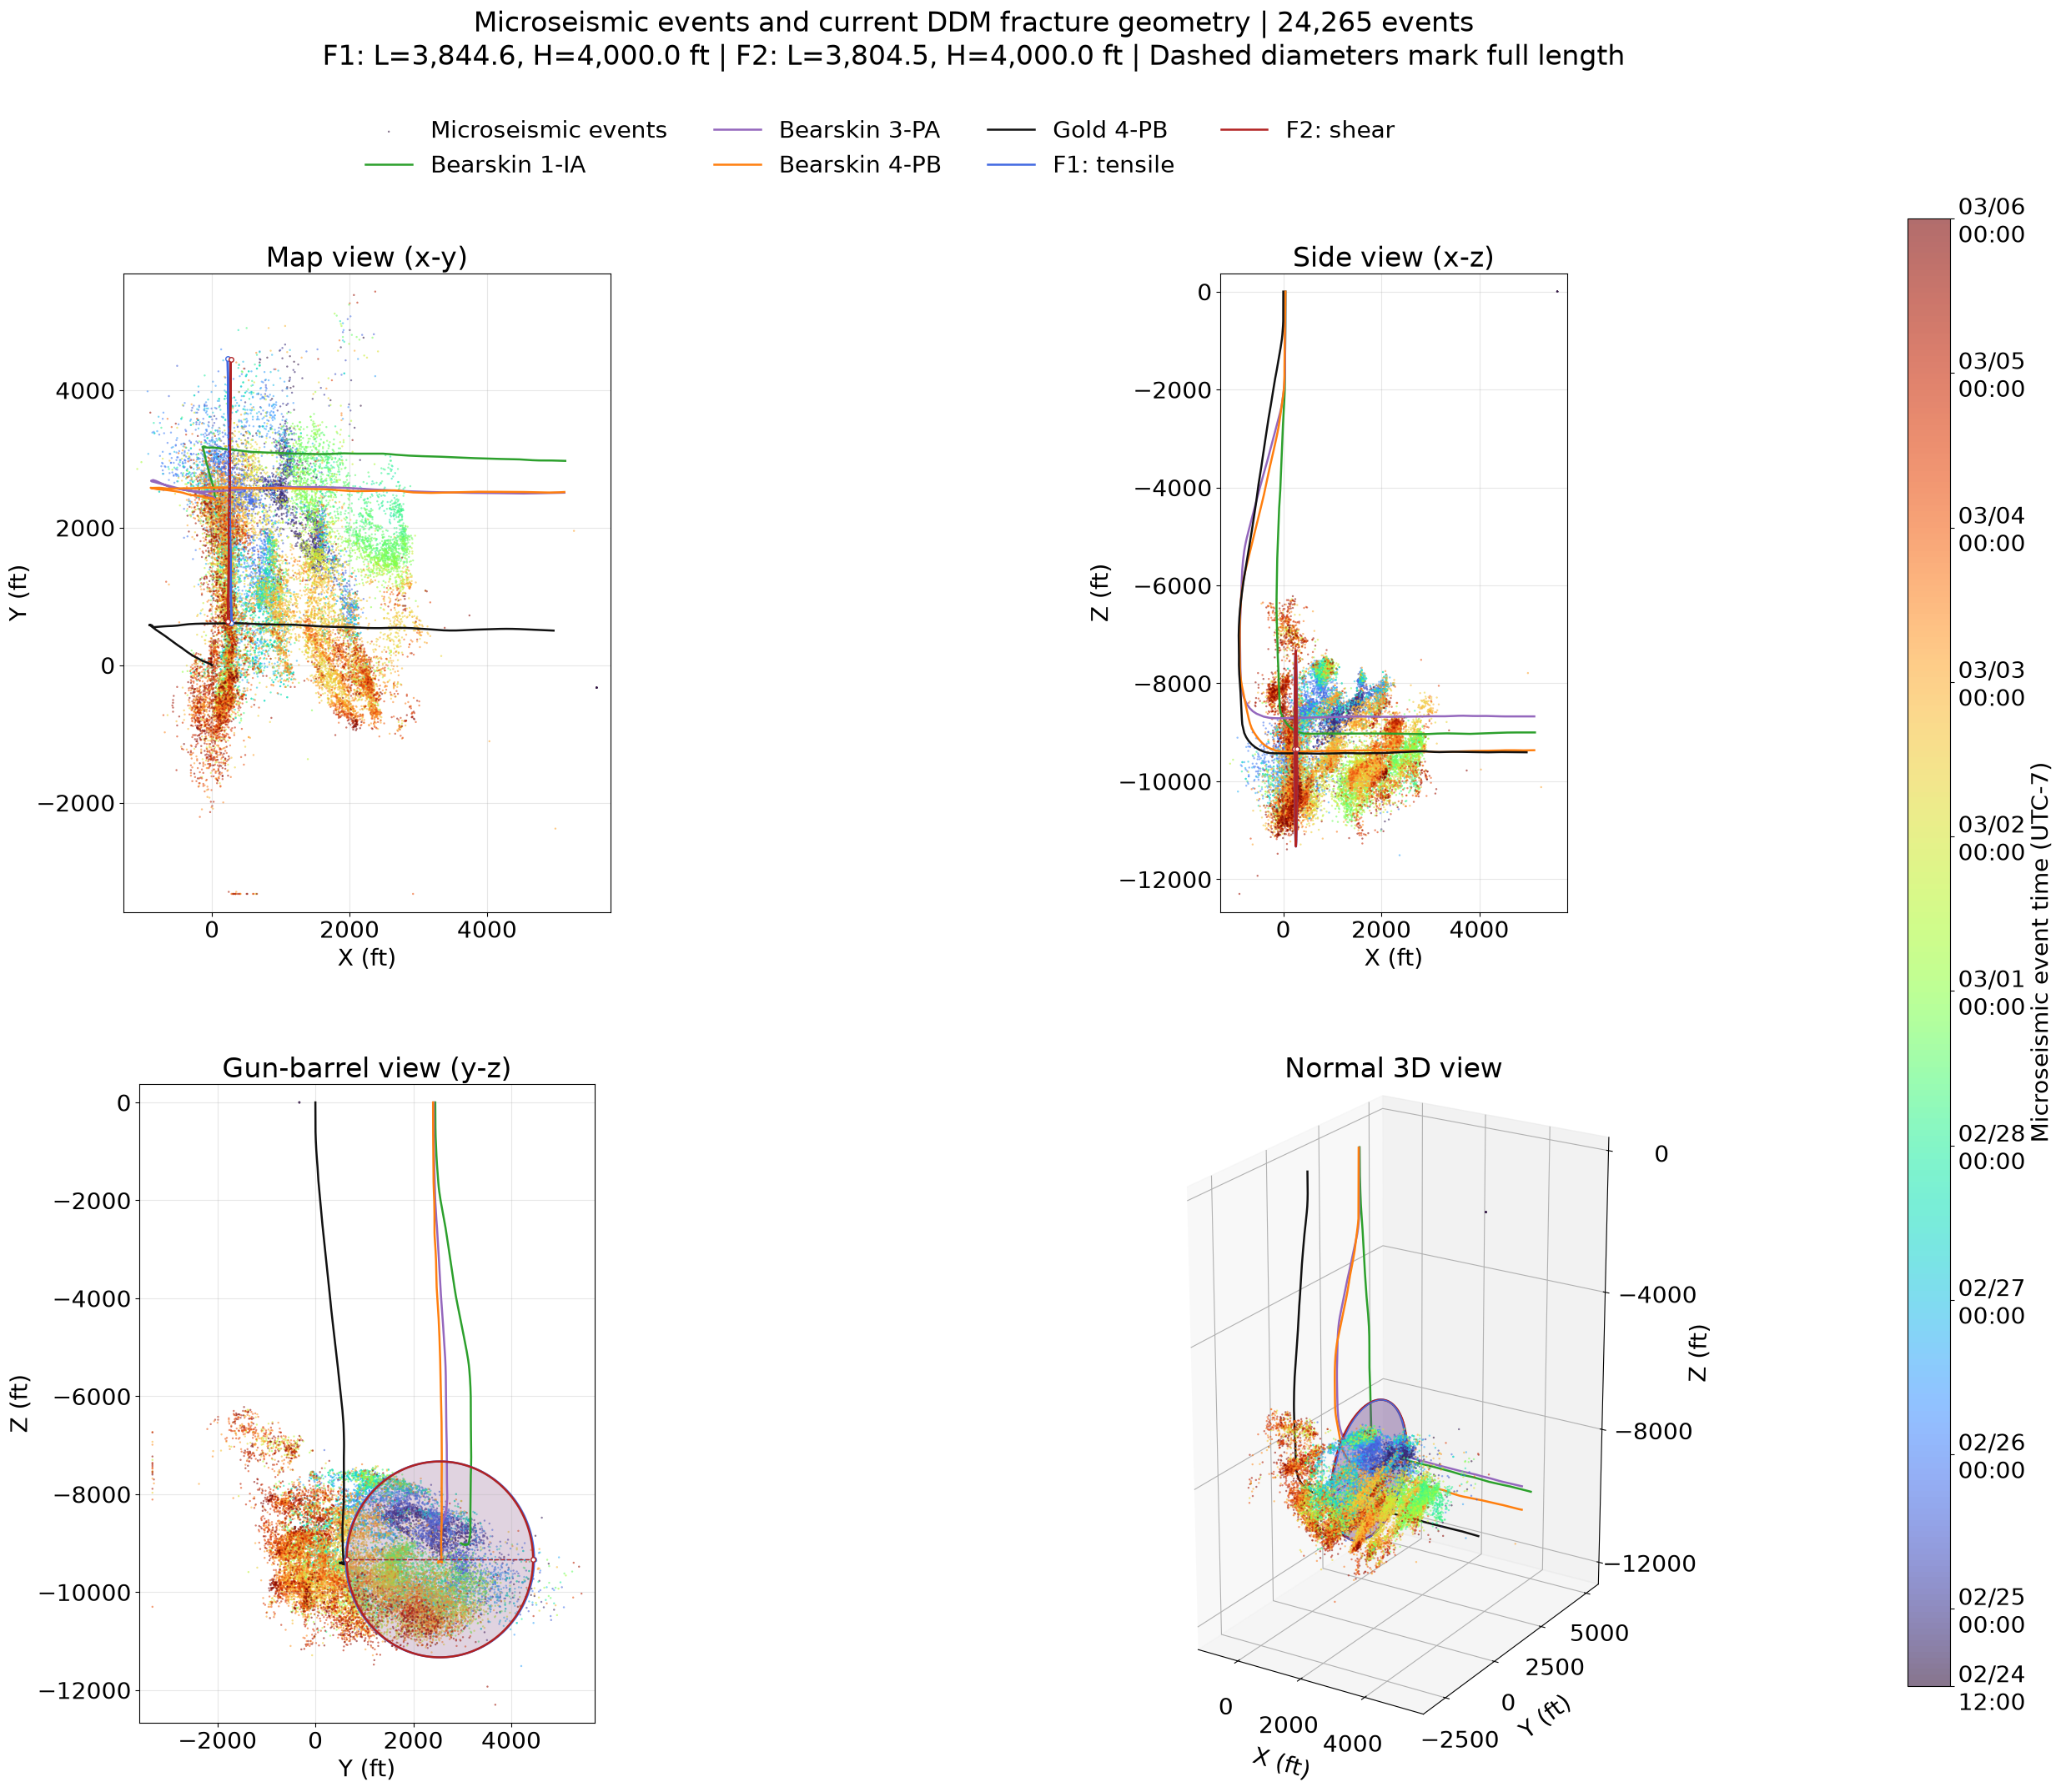

In [13]:
# Cell 15 | Modified 2026-09-20 22:34:05 MDT — Geometry: four well and microseismic views, unchanged tensile plane
# Purpose: Display microseismicity, well trajectories and both fixed planes in four views with enlarged plot text.
context=geometry_diagnostics.load_geometry_context(V1.parent.parent/'data/Microseismic Catalog/Microseismic_202502_202505_feet.csv',V1.parent.parent/'data/Well Geometries',T1,T3)
fig=geometry_diagnostics.microseismic_geometry(geometries,context=context,shape='ellipse')
# Enlarge the existing four-view geometry figure without changing geometry.
fig.set_size_inches(28,22)
fig._suptitle.set_fontsize(24)
from matplotlib.ticker import MaxNLocator
ax3=fig.axes[3]
for axis in [ax3.xaxis,ax3.yaxis,ax3.zaxis]:
    axis.set_major_locator(MaxNLocator(4))
    axis.set_tick_params(labelsize=20,pad=10)
ax3.zaxis.set_tick_params(pad=30)
ax3.set_xlabel('X (ft)',labelpad=20)
ax3.set_ylabel('Y (ft)',labelpad=20)
ax3.set_zlabel('Z (ft)',labelpad=50)
save_figure(fig,'baseline_geometry')

### Cell 16 | Pressure, slip evolution and large waterfall diagnostics

Show injection pressure with recorded stage numbers, slip histories, and both observed and simulated waterfalls.

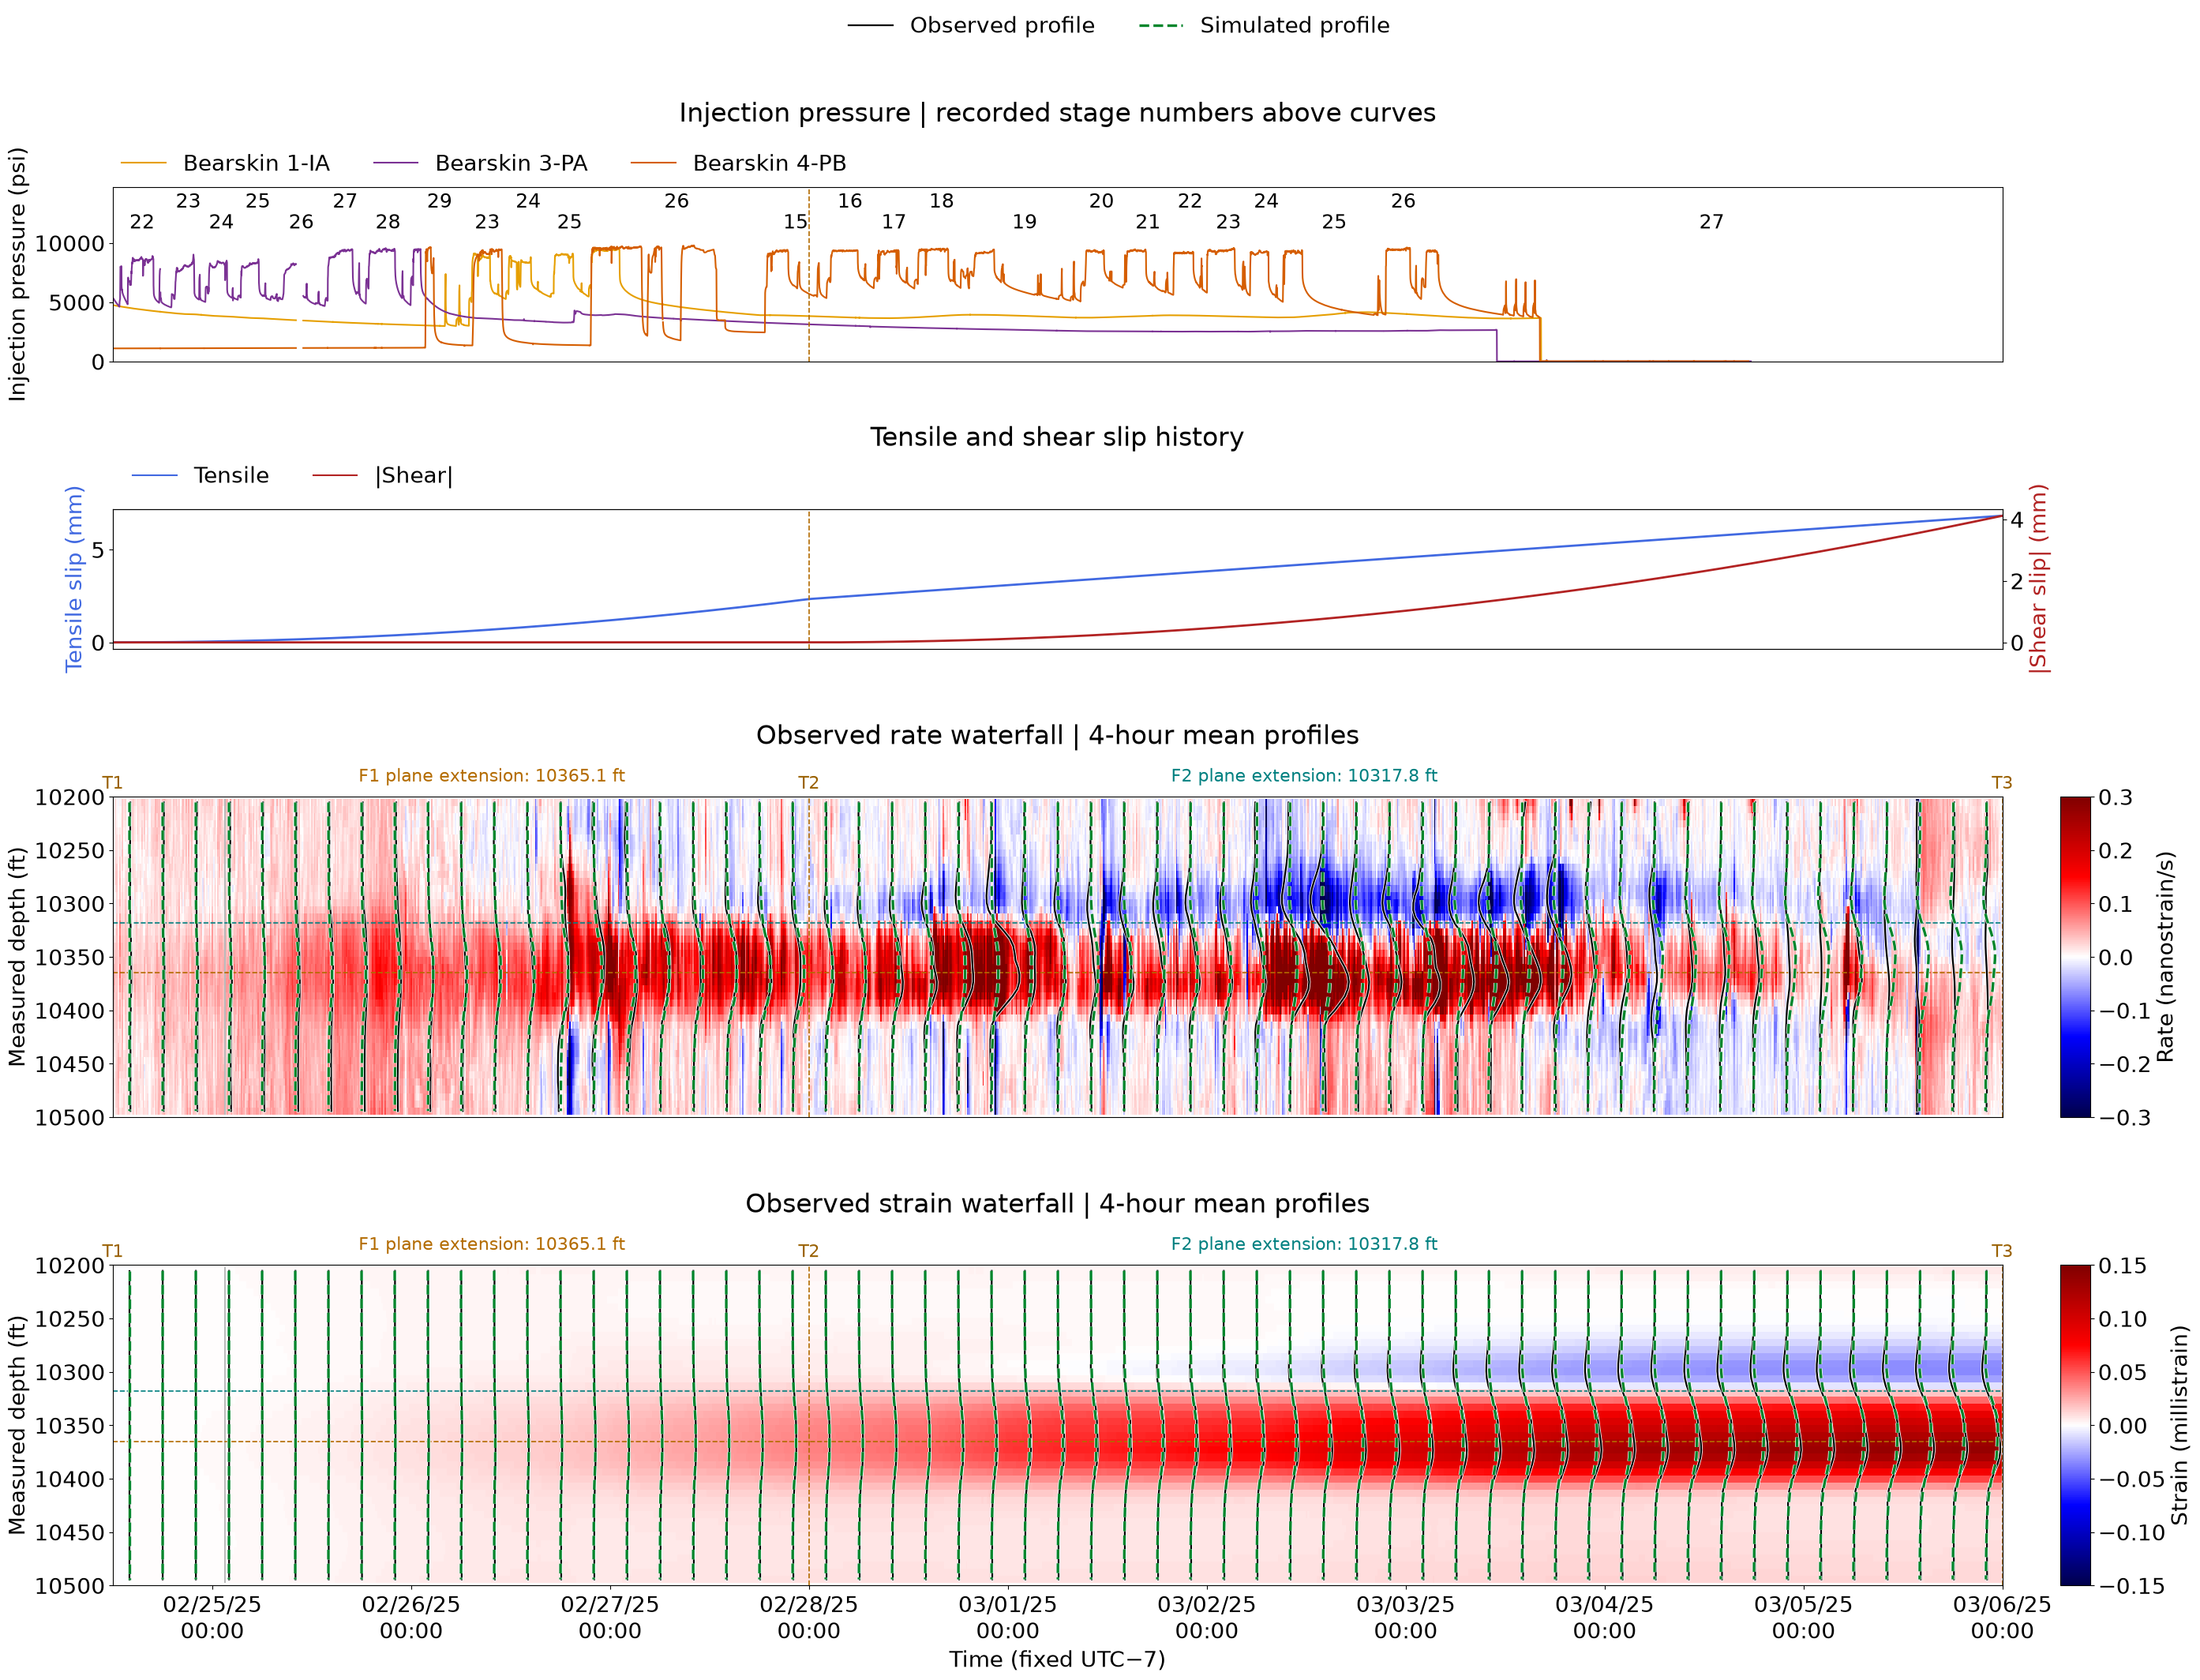

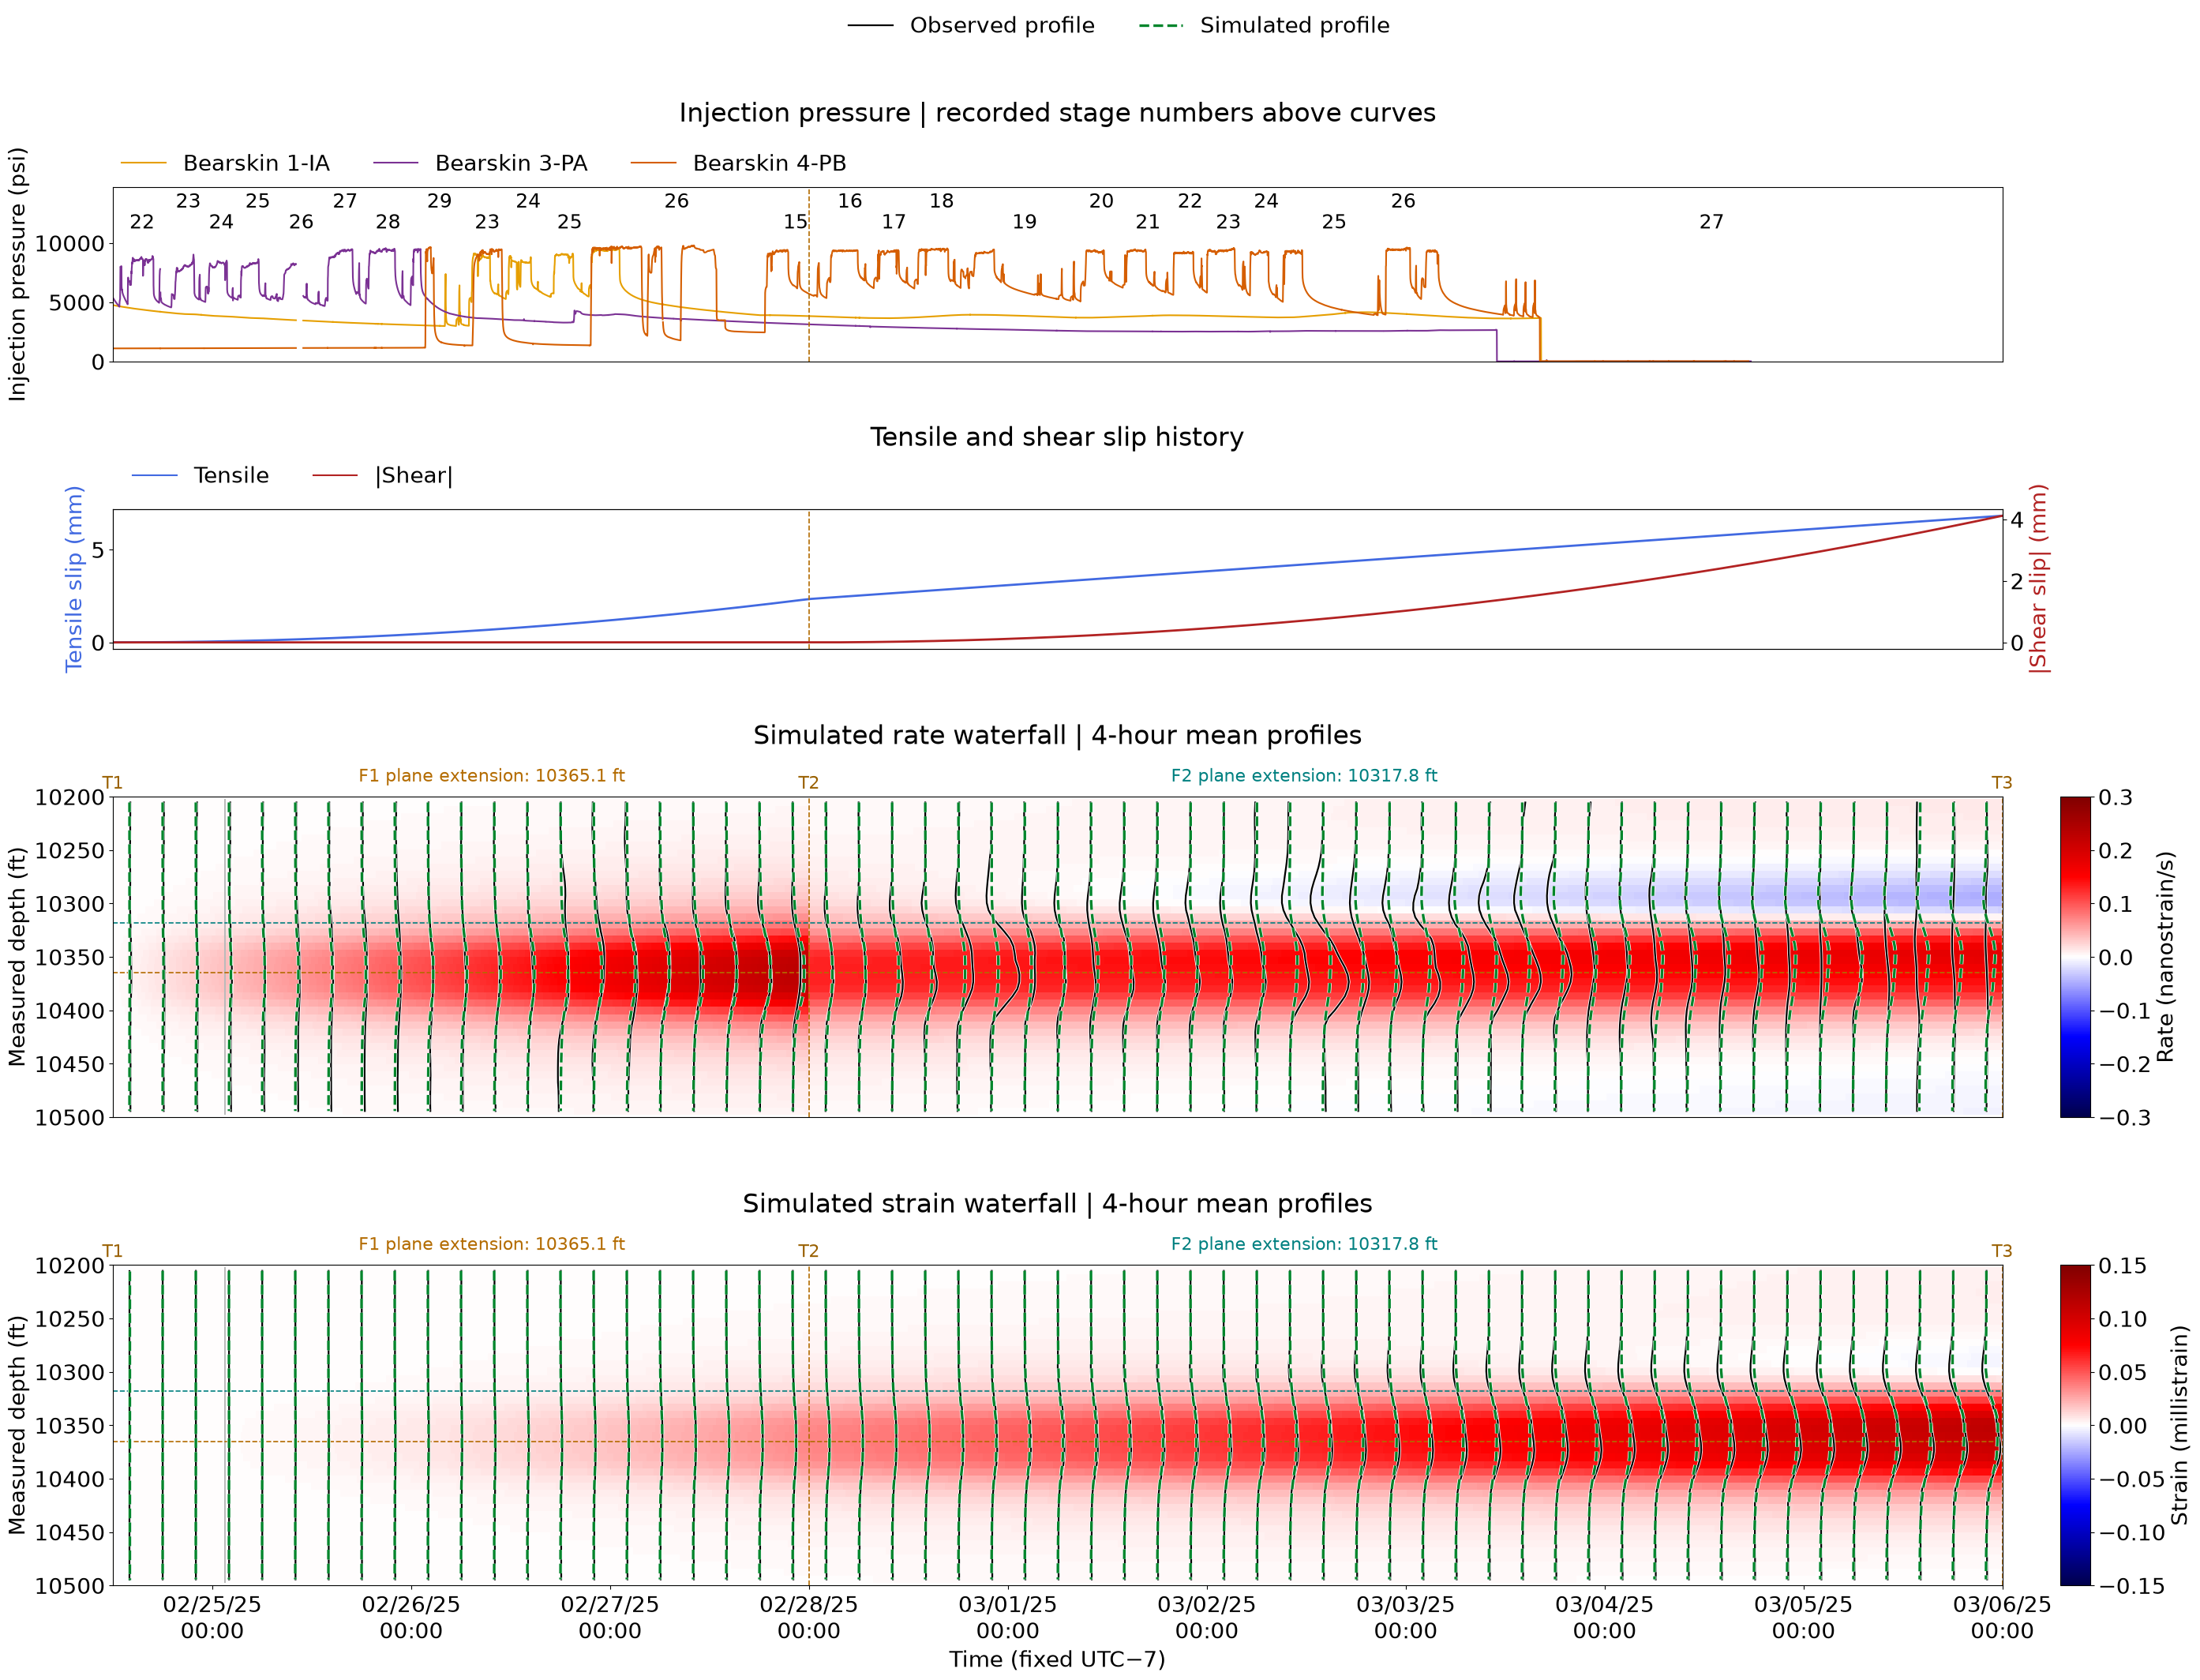

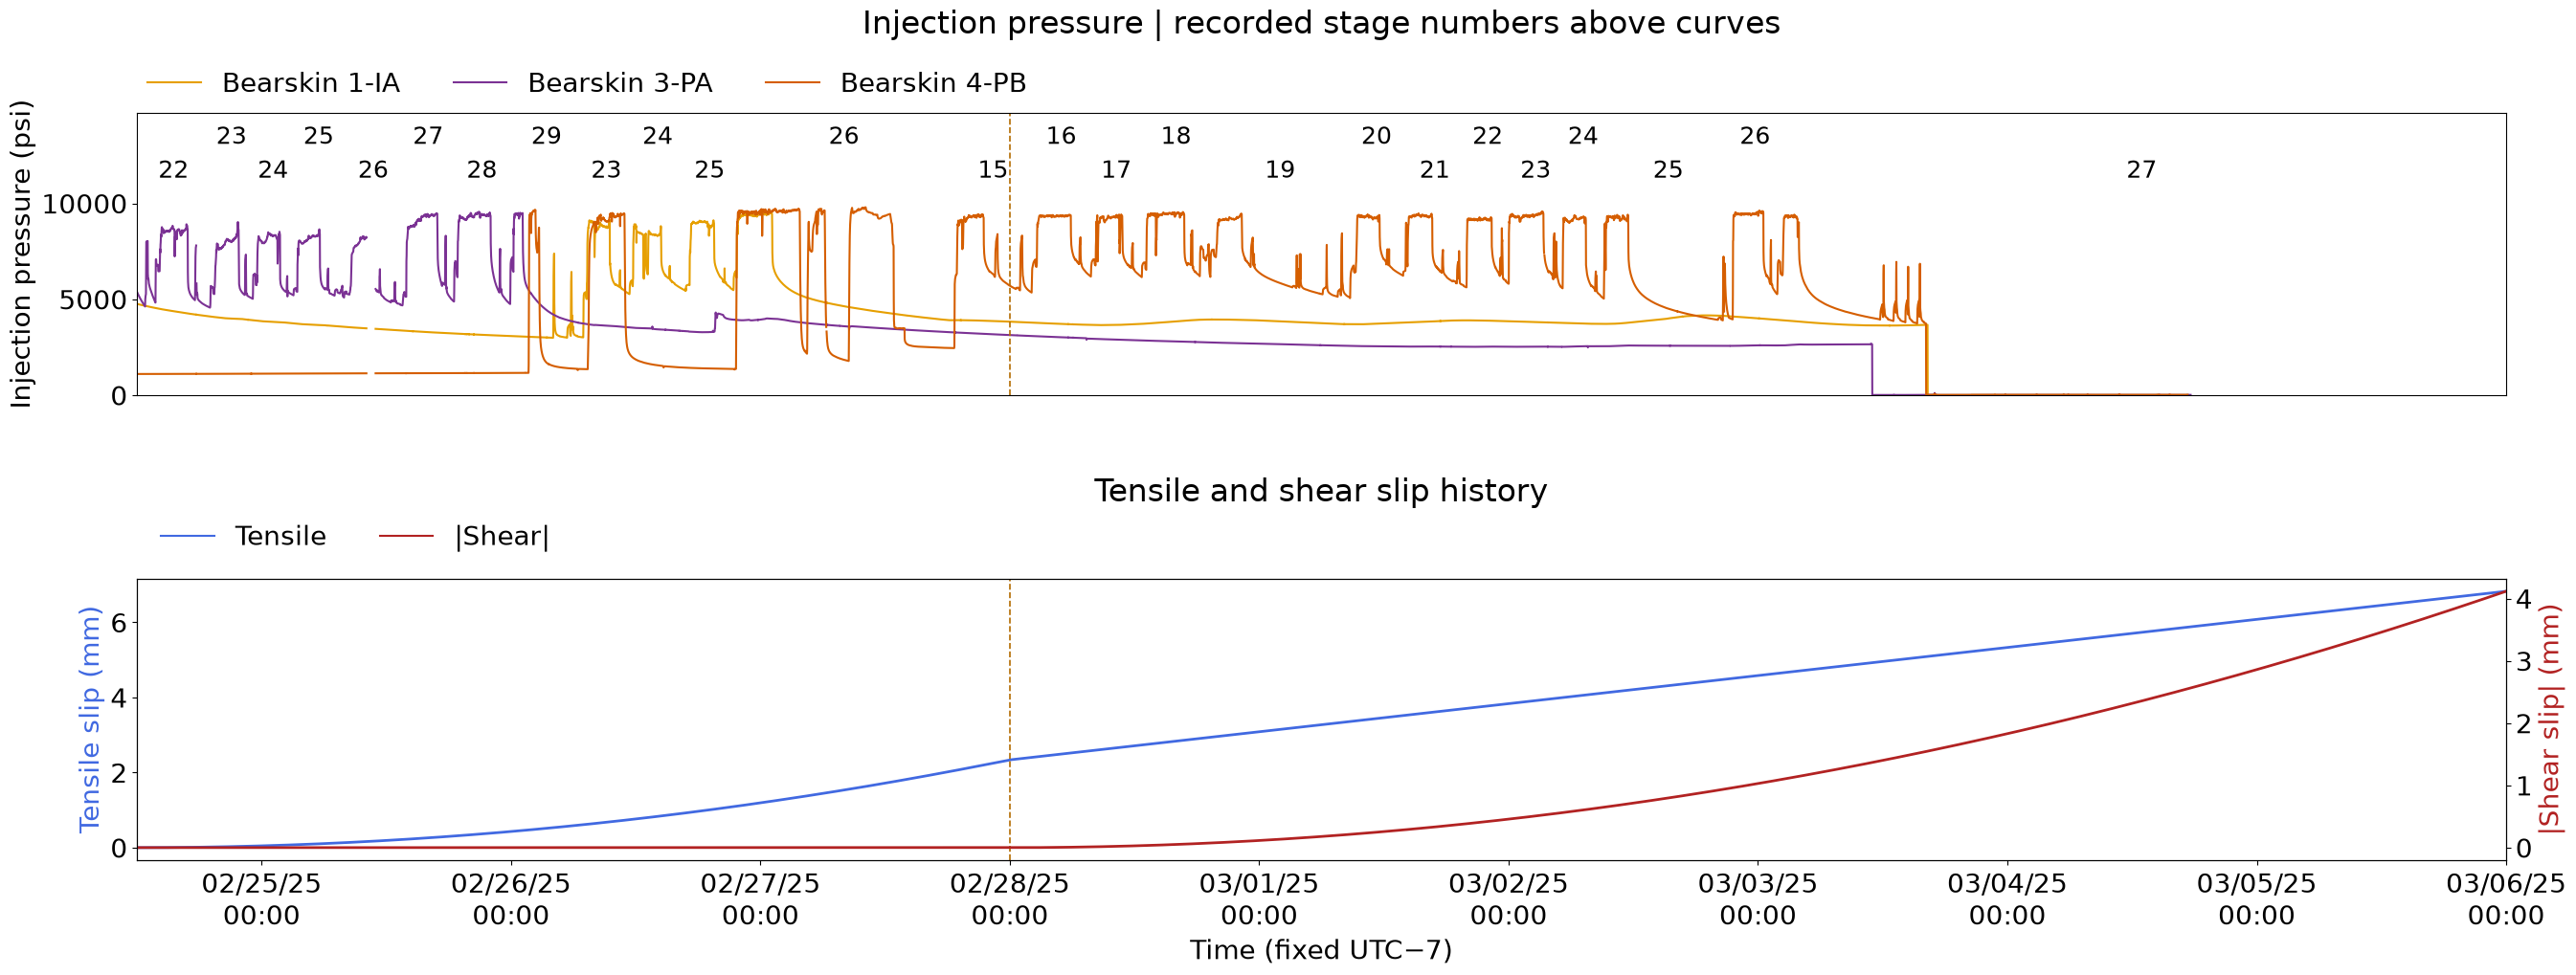

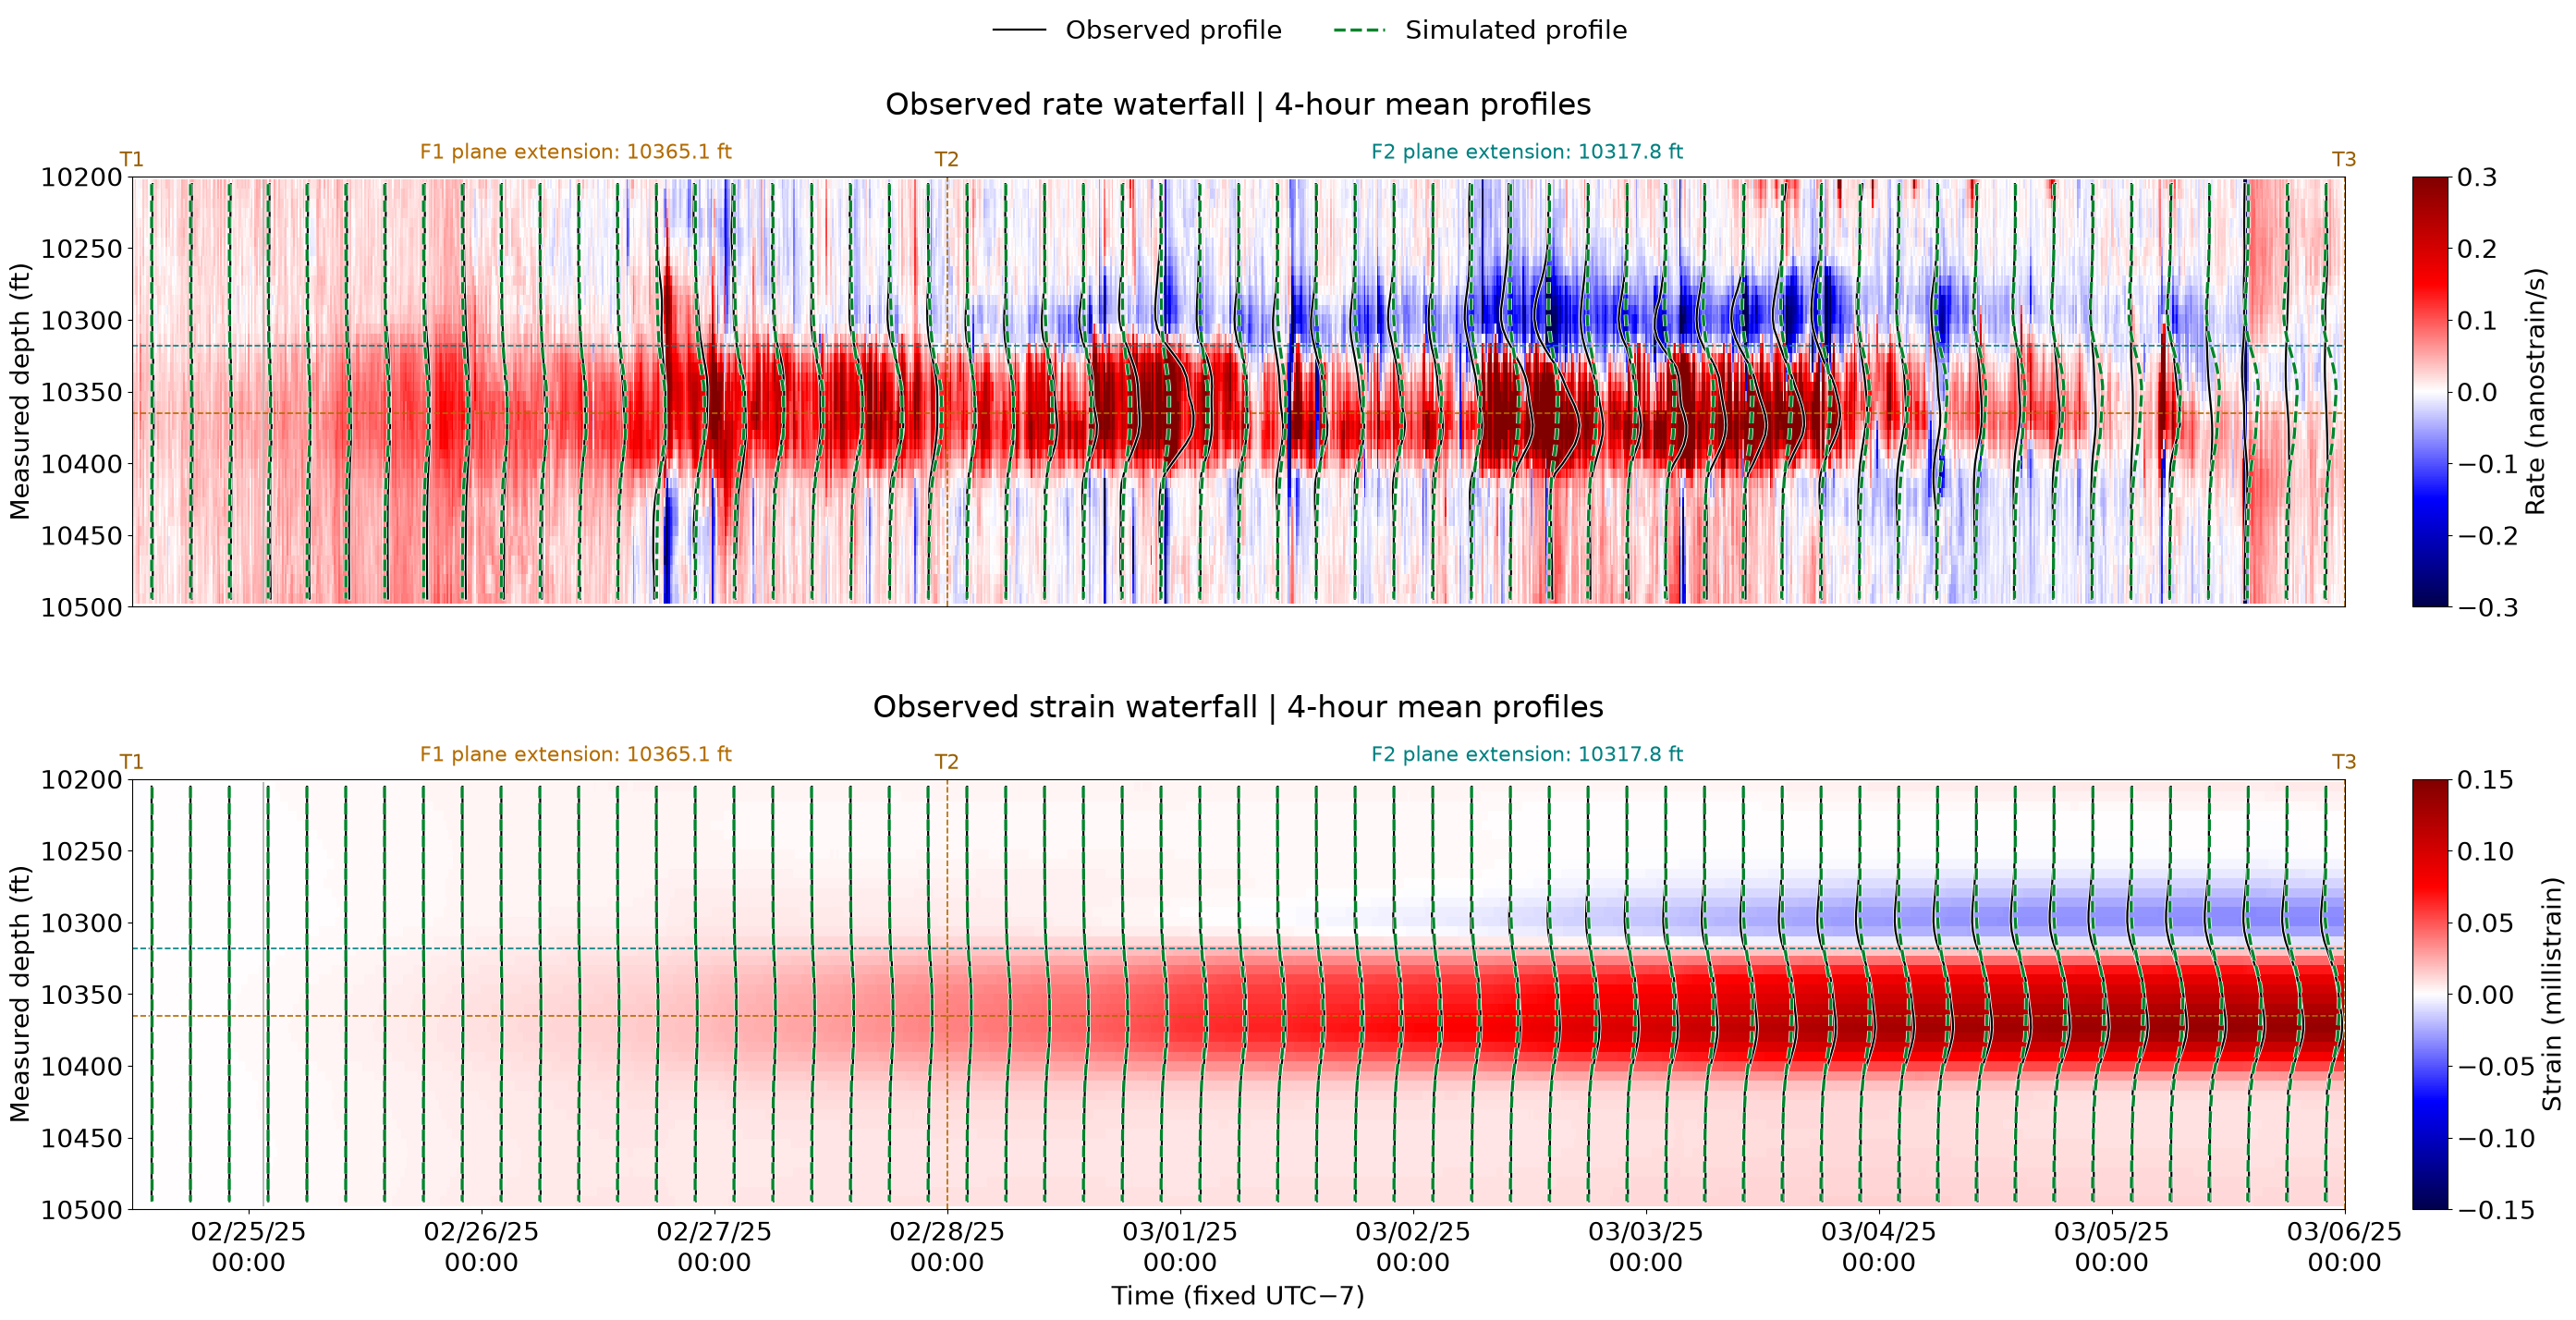

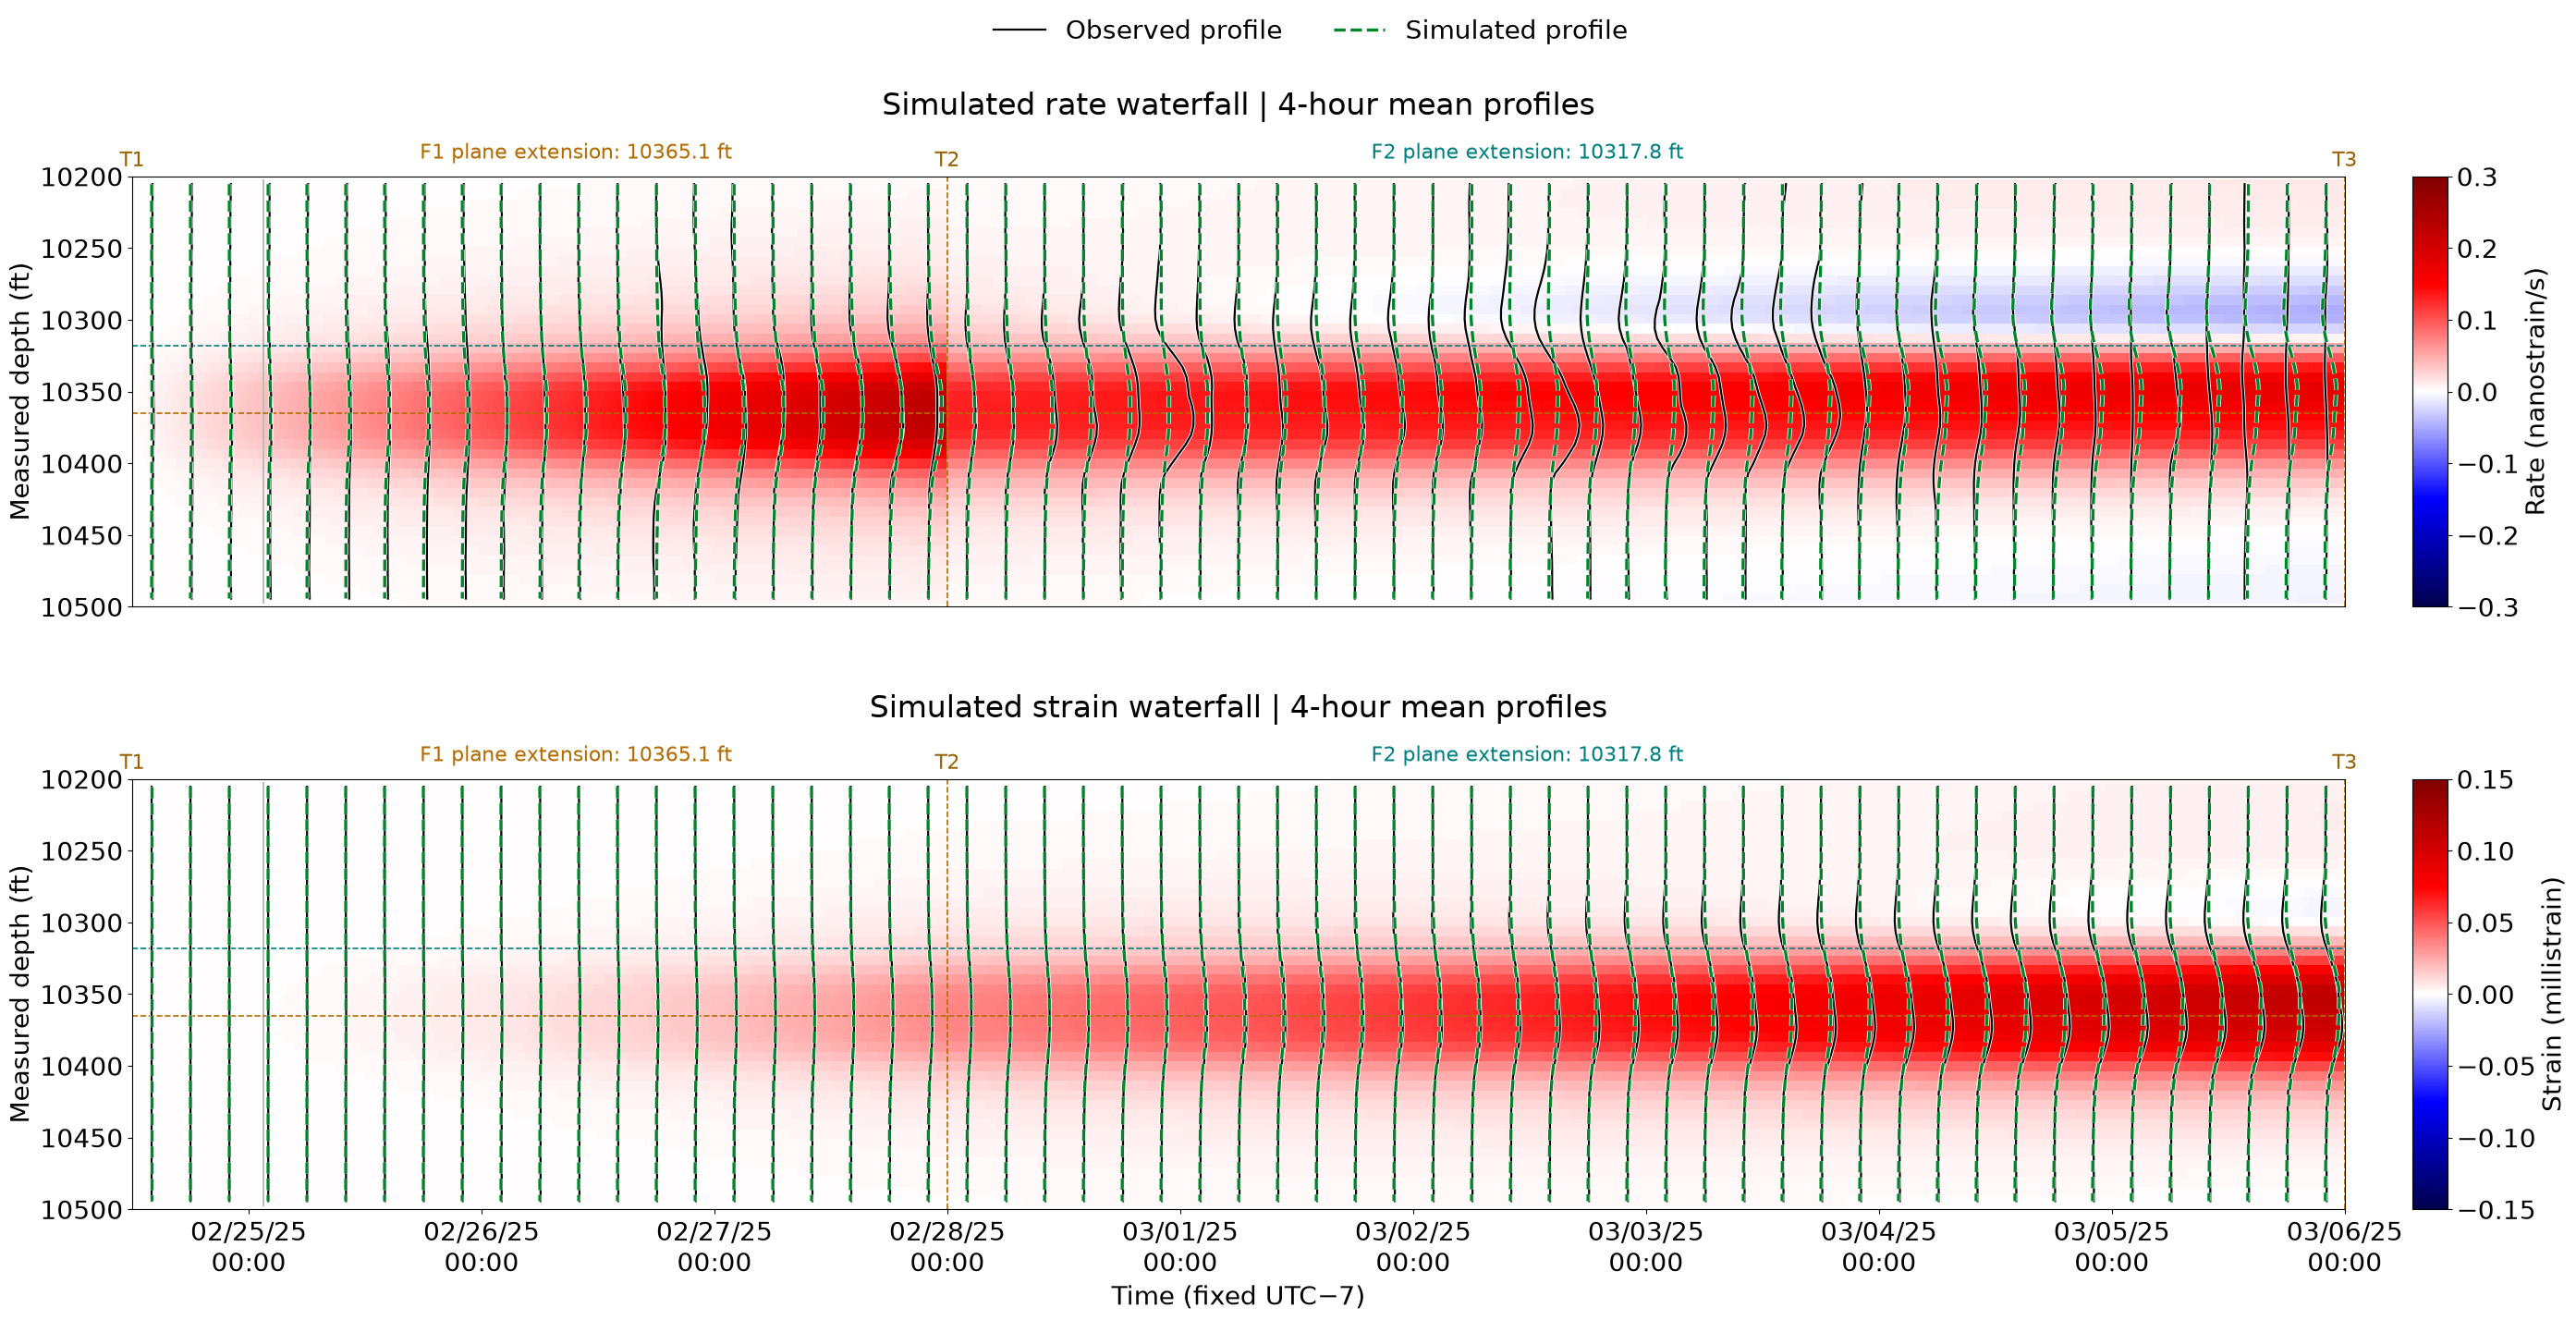

In [14]:
# Cell 16 | Modified 2026-09-20 22:34:05 MDT — Pressure, slip evolution and large waterfall diagnostics
# Purpose: Show injection pressure with recorded stage numbers, slip histories, and both observed and simulated waterfalls.
injection=pressure_data()
injection.to_csv(OUT/'injection_pressure.csv',index=False)
plot_summary(obs,baseline,injection,f'Baseline_{FIT_TARGET}_fit_prescribed_time_laws')
plot_summary(obs,baseline,injection,f'Baseline_{FIT_TARGET}_fit_prescribed_time_laws',background='simulated')
plot_pressure_slip(obs,baseline,injection,f'Baseline_{FIT_TARGET}_fit_prescribed_time_laws')
plot_comparison(obs,baseline,'baseline')